# Entrega 2: Comparação de seis famílias com validação cruzada
**Dupla:** Joaquim Veras e Luiz Henrique Falcão  

## Seção 0 - Instruções
Base: **Brain Stroke**, com 4.981 registros, 10 preditores e o alvo `stroke`.
A divisão da E1 é reproduzida com **semente 10**. Treino e validação formam o desenvolvimento.

O CSV e as implementações autorais estão neste notebook. Os resultados são persistidos no Google Drive. As buscas, curvas e estudos autorais são concluídos antes da etapa de teste. A opção `EXECUTAR_TESTE_SEMENTE10`, na célula de configuração, controla essa etapa. Resultados já registrados são recuperados.

**Tempo aproximado da execução completa:** cerca de 35 minutos de CPU para o
desenvolvimento (buscas 16,4 min; curvas 3,9 min; estudos autorais 13,7 min,
conforme o apêndice ao final). As etapas são salvas individualmente no Google
Drive e as execuções seguintes recuperam os resultados existentes, concluindo
em segundos.

Para exportar: **Reiniciar e executar tudo**, conferir as saídas e gerar o PDF.

In [ ]:
import sys, time, json, hashlib, warnings, datetime, platform, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, validation_curve
from sklearn.metrics import (
    balanced_accuracy_score, accuracy_score, f1_score, recall_score,
    precision_score, roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, make_scorer
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression, Perceptron as PerceptronSklearn
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning

SEMENTE = 10
TEST_SIZE, VAL_SIZE, K_FOLDS = 0.20, 0.25, 5
METRICA = 'balanced_accuracy'
VERSAO_PROTOCOLO = 'e2-semente10-refatorada-v2'
EXECUTAR_TESTE_SEMENTE10 = True
LINK_COLAB = 'https://colab.research.google.com/drive/1GyyIjuEYvcJepdPaLz9NSfjEFAIkv5zw#scrollTo=GlXDQtXQZQ_B'

T_INICIO = time.perf_counter()
np.random.seed(SEMENTE)
limite_threads = threadpool_limits(limits=1)
pd.set_option('display.precision', 4)
pd.set_option('display.max_colwidth', 100)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
VERSOES = {'python': platform.python_version(), 'numpy': np.__version__,
           'pandas': pd.__version__, 'sklearn': sklearn.__version__}
print('Ambiente:', VERSOES)
print('Semente:', SEMENTE, '| Métrica:', METRICA)
print('Etapas:', 'desenvolvimento e teste' if EXECUTAR_TESTE_SEMENTE10 else 'desenvolvimento')
if LINK_COLAB.strip():
    display(Markdown(f'**Notebook:** [acesso de leitura]({LINK_COLAB.strip()})'))


Ambiente: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'sklearn': '1.6.1'}
Semente: 10 | Métrica: balanced_accuracy
Etapas: desenvolvimento e teste


**Notebook:** [acesso de leitura](https://colab.research.google.com/drive/1GyyIjuEYvcJepdPaLz9NSfjEFAIkv5zw#scrollTo=GlXDQtXQZQ_B)

In [ ]:
try:
    from google.colab import drive
except ImportError:
    RAIZ_NOVA = Path.cwd() / 'artefatos_e2_semente10'
else:
    drive.mount('/content/drive')
    RAIZ_NOVA = Path('/content/drive/MyDrive/aprendizado_de_maquina_1/artefatos_e2_semente10')
RAIZ_NOVA.mkdir(parents=True, exist_ok=True)
print('Resultados:', RAIZ_NOVA)

def normalizar(valor):
    if isinstance(valor, np.ndarray):
        return normalizar(valor.tolist())
    if isinstance(valor, np.generic):
        return normalizar(valor.item())
    if isinstance(valor, dict):
        return {str(k): normalizar(v) for k, v in valor.items()}
    if isinstance(valor, (list, tuple)):
        return [normalizar(v) for v in valor]
    if valor is None or isinstance(valor, (str, bool, int, float)):
        return valor
    raise TypeError(f'Tipo não serializável: {type(valor)}')

def texto_json(valor):
    return json.dumps(normalizar(valor), ensure_ascii=False, sort_keys=True, indent=2, allow_nan=False)

def digest(valor):
    return hashlib.sha256(texto_json(valor).encode('utf-8')).hexdigest()

def ler_json(arquivo):
    return json.loads(Path(arquivo).read_text(encoding='utf-8'))

def salvar_json(arquivo, valor):
    arquivo = Path(arquivo)
    temporario = arquivo.with_name(arquivo.name + '.tmp')
    temporario.write_text(texto_json(valor), encoding='utf-8')
    temporario.replace(arquivo)

def agora():
    return datetime.datetime.now(datetime.timezone.utc).isoformat()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Resultados: /content/drive/MyDrive/aprendizado_de_maquina_1/artefatos_e2_semente10


In [ ]:
#@title Carregar o CSV incorporado
import base64, zlib, io
CSV_BASE64 = '...'
csv_bytes = zlib.decompress(base64.b64decode(CSV_BASE64, validate=True))
HASH_CSV = hashlib.sha256(csv_bytes).hexdigest()
assert HASH_CSV == '7a984ab825f586aadc6314c58f86315c59e194db2cdcaacf2d138c8bba5d1b8d', 'CSV incorporado alterado.'
dados = pd.read_csv(io.BytesIO(csv_bytes))
assert dados.shape == (4981, 11) and set(dados['stroke'].unique()) == {0, 1}
print('Base carregada:', dados.shape, '| SHA-256:', HASH_CSV)


Base carregada: (4981, 11) | SHA-256: 7a984ab825f586aadc6314c58f86315c59e194db2cdcaacf2d138c8bba5d1b8d


## Seção 1 - Problema e dados
**Pergunta:** em que medida os atributos disponíveis permitem distinguir os registros com
`stroke=1` dos registros com `stroke=0` neste conjunto?

O alvo registra ocorrência de AVC. Estes dados não estabelecem uma janela temporal de
predição nem demonstram desempenho clínico prospectivo. O trabalho é uma comparação
acadêmica de classificadores; não permite concluir que o modelo prevê um AVC futuro.

**Fonte:** [Brain Stroke Dataset, Jillani SofTech, Kaggle](https://www.kaggle.com/datasets/jillanisofttech/brain-stroke-dataset).
Os metadados públicos do Kaggle informam a licença **Database: Open Database, Contents: Database Contents**
(consulta em 21/10/2026).
O arquivo disponibilizado tem 4.981 linhas, 10 preditores e o alvo.

### Atributos


| Atributo | Tipo | Significado |
|---|---|---|
| `gender` | categórico | Sexo do paciente (Male / Female) |
| `age` | numérico | Idade em anos |
| `hypertension` | binário | 1 se tem hipertensão, 0 caso contrário |
| `heart_disease` | binário | 1 se tem doença cardíaca, 0 caso contrário |
| `ever_married` | categórico | Já foi casado (Yes / No) |
| `work_type` | categórico | Tipo de trabalho (Private, Self-employed, Govt_job, children) |
| `Residence_type` | categórico | Zona de moradia (Urban / Rural) |
| `avg_glucose_level` | numérico | Nível médio de glicose no sangue |
| `bmi` | numérico | Índice de massa corporal |
| `smoking_status` | categórico | Hábito de fumar (never smoked, formerly smoked, smokes, Unknown) |
| **`stroke`** | **alvo binário** | **1 = teve AVC (classe positiva), 0 = não teve** |

In [ ]:
display(dados.head())
display(dados['stroke'].value_counts().sort_index().rename_axis('stroke').to_frame('registros'))


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
3,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


,registros
stroke,
0,4733
1,248


## Seção 2 - Mesma divisão e semente
A referência é a entrega 1.
Reproduzimos as duas chamadas estratificadas com `random_state=10`: 20% para teste e, do restante, 25% para validação. A ordem das linhas do CSV é preservada.

Os índices visíveis nas saídas da E1 são conferidos; a divisão completa e o hash dos dados ficam registrados em um manifesto. O desenvolvimento é a concatenação de treino e validação da E1, nessa ordem.

In [ ]:
X = dados.drop(columns=['stroke'])
y = dados['stroke']
X_tmp, X_teste, y_tmp, y_teste = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEMENTE)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_tmp, y_tmp, test_size=VAL_SIZE, stratify=y_tmp, random_state=SEMENTE)
X_dev = pd.concat([X_treino, X_val])
y_dev = pd.concat([y_treino, y_val])

assert SEMENTE == 10
assert X_treino.index[:5].tolist() == [4046, 1099, 1664, 4503, 3659]
assert X_treino.index[-5:].tolist() == [4831, 1058, 1434, 4008, 4807]
assert not set(X_treino.index) & set(X_val.index)
assert not set(X_dev.index) & set(X_teste.index)
assert sorted(X_dev.index.tolist() + X_teste.index.tolist()) == list(range(len(dados)))

manifesto = {'fonte': 'Joaquim_e_Luiz_restaurado (6).ipynb',
    'sha256_csv': HASH_CSV, 'semente': SEMENTE,
    'treino': X_treino.index.tolist(), 'validacao': X_val.index.tolist(),
    'teste': X_teste.index.tolist()}
arq_divisao = RAIZ_NOVA / 'divisao_e1_refatorada.json'
if arq_divisao.exists():
    assert ler_json(arq_divisao) == manifesto, 'Os índices diferem do manifesto salvo.'
else:
    salvar_json(arq_divisao, manifesto)
display(pd.DataFrame({
    'registros': [len(y_treino), len(y_val), len(y_dev), len(y_teste)],
    'casos AVC': [int(y_treino.sum()), int(y_val.sum()), int(y_dev.sum()), 'teste'],
    'proporção AVC': [y_treino.mean(), y_val.mean(), y_dev.mean(), 'teste']
}, index=['Treino E1', 'Validação E1', 'Desenvolvimento', 'Teste E1']))
print('Índices e semente conferidos com a E1.')


,registros,casos AVC,proporção AVC
Treino E1,2988,148,0.0495
Validação E1,996,50,0.0502
Desenvolvimento,3984,198,0.0497
Teste E1,997,teste,teste


Índices e semente conferidos com a E1.


## Seção 3 - Protocolo
**CV estratificada com 5 folds**, embaralhamento e semente 10, apenas no desenvolvimento
(3.984 registros). Os mesmos folds são usados em todas as famílias e curvas; não há subamostragem.

**Pré-processamento:** contínuos (`age`, `avg_glucose_level`, `bmi`): mediana + StandardScaler;
binários (`hypertension`, `heart_disease`): moda, preservando 0/1; categóricos: moda + OneHotEncoder
com `drop='if_binary'` e `handle_unknown='ignore'`. Todos dentro do Pipeline, ajustados em cada fold.
`Unknown` em tabagismo é uma categoria explícita. Nenhum transformador é ajustado fora do Pipeline.

**Métrica principal:** acurácia balanceada = média do recall das duas classes. A acurácia
simples será secundária porque prever sempre zero já acerta cerca de 95% da base, mas tem
acurácia balanceada 0,50. O critério equilibra os recalls, sem representar custos clínicos.

**Seleção:** maior média CV por família; empate exato segue a ordem declarada da grade.
Campeão geral: maior média CV, com desempate pelo nome da família. As curvas estudam a
regra de 1 EP, mas não substituem o critério de maior média usado para os campeões.
Desvio amostral (`ddof=1`) e EP = desvio / raiz(5). Os folds compartilham dados de treino:
EP e regra de 1 EP são resumos heurísticos, não testes de significância ou equivalência.

**Limitações do desenho:** selecionar e reportar o melhor escore na mesma CV introduz otimismo
de seleção. Não se trata de validação cruzada aninhada. Algumas famílias testam pesos de classe
e outras não: a comparação é entre os pipelines declarados, sem isolar o efeito causal do modelo.

In [ ]:
COLS_NUM = ['age', 'avg_glucose_level', 'bmi']
COLS_BIN = ['hypertension', 'heart_disease']
COLS_CAT = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
assert set(COLS_NUM + COLS_BIN + COLS_CAT) == set(X.columns)
def novo_preprocessador():
    return ColumnTransformer([
        ('num', Pipeline([('imput', SimpleImputer(strategy='median')),
                          ('escala', StandardScaler())]), COLS_NUM),
        ('bin', SimpleImputer(strategy='most_frequent'), COLS_BIN),
        ('cat', Pipeline([('imput', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False))]), COLS_CAT)])
def montar_pipeline(modelo):
    return Pipeline([('prep', novo_preprocessador()), ('modelo', modelo)])
cv = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEMENTE)
FOLDS = list(cv.split(X_dev, y_dev))
display(pd.DataFrame([{'fold': i+1, 'treino': len(tr), 'validacao': len(va),
    'positivos_validacao': int(y_dev.iloc[va].sum())} for i,(tr,va) in enumerate(FOLDS)]))


,fold,treino,validacao,positivos_validacao
0,1,3187,797,39
1,2,3187,797,40
2,3,3187,797,40
3,4,3187,797,40
4,5,3188,796,39


## Seção 4 - Busca de hiperparâmetros por CV
As seis famílias passam por GridSearchCV, com escores de treino e validação. O melhor Pipeline
é reajustado no desenvolvimento completo. Avisos de convergência são contabilizados e exibidos;
nenhum erro de ajuste é convertido silenciosamente em escore (`error_score='raise'`).

| Família | Justificativa da grade inicial |
|---|---|
| Árvore | Profundidades de 1 a 15 e livre; folhas de 1 a 50; Gini/entropia. Pesos balanceados fixos. |
| kNN | k de 1 a 51; votos uniforme/distância; Manhattan/euclidiana. k=1 é o limite natural. |
| Gaussiano NB | Suavização de variâncias de 1e-11 a 1e-3, em escala logarítmica. |
| Logística | C de 1e-3 a 1e3; sem/com pesos balanceados. Menor C aumenta regularização. |
| Perceptron | **L2 ativa**, alpha de 1e-6 a 1e-1; eta0 em 0,01, 0,1, 1; sem/com pesos balanceados. |
| MLP | Camadas (16), (32), (64), (32,16); alpha de 1e-4 a 10, solver Adam, até 1000 iterações. |

**Regra de extensão:** se o melhor parâmetro numérico estiver numa
borda não natural, estender esse lado uma vez: fatores 100 para escalas logarítmicas e 2 para
inteiros. Reexecutar a grade ampliada inteira, nos mesmos folds. Se a nova solução continuar
na borda, registrar explicitamente a limitação de orçamento, sem afirmar ótimo global.
Limites naturais: profundidade 1/livre, k=1, tamanho mínimo de folha=1. Categorias (critério,
p, pesos e arquiteturas) são alternativas discretas; não tratamos a lista como eixo numérico.
Cada arquitetura MLP também é comparada explicitamente, sem supor ordem total de complexidade.

O limite de uma extensão controla o custo da busca e é aplicado igualmente antes da nova avaliação final do protocolo corrigido, reconhecendo o histórico de acesso a resultados anteriores.

In [ ]:
FAMILIAS = {
    'Árvore de decisão': (
        DecisionTreeClassifier(class_weight='balanced', random_state=SEMENTE),
        {'modelo__max_depth':        [1, 2, 3, 4, 5, 6, 8, 10, 15, None],
         'modelo__min_samples_leaf': [1, 5, 10, 20, 50],
         'modelo__criterion':        ['gini', 'entropy']}),

    'kNN': (
        KNeighborsClassifier(),
        {'modelo__n_neighbors': [1, 3, 5, 7, 9, 11, 15, 21, 31, 51],
         'modelo__weights':     ['uniform', 'distance'],
         'modelo__p':           [1, 2]}),

    'Naive Bayes': (
        GaussianNB(),
        {'modelo__var_smoothing': np.logspace(-11, -3, 9)}),

    'Regressão logística': (
        LogisticRegression(max_iter=2000, random_state=SEMENTE),
        {'modelo__C':            np.logspace(-3, 3, 7),
         'modelo__class_weight': [None, 'balanced']}),

    'Perceptron': (
        PerceptronSklearn(penalty="l2", max_iter=3000, random_state=SEMENTE),
        {'modelo__alpha':        np.logspace(-6, -1, 6),
         'modelo__eta0':         [0.01, 0.1, 1.0],
         'modelo__class_weight': [None, 'balanced']}),

    'MLP': (
        MLPClassifier(max_iter=1000, random_state=SEMENTE),
        {'modelo__hidden_layer_sizes': [(16,), (32,), (64,), (32, 16)],
         'modelo__alpha':              np.logspace(-4, 1, 6)}),
}


### Implementações autorais — Perceptron e MLP
**Código-base: Joaquim Veras.** As implementações complementam a comparação principal.

Foi mantida uma única classe `Mlp`: camadas de largura `j`, ReLU, duas saídas, erro quadrático e amostragem com reposição. Os escores da MLP não são probabilidades.

A inicialização uniforme positiva usa escala 0,1. Os nomes `predcit` e `predicit` são preservados. O método autoral `precisao` calcula acurácia; as métricas do estudo são calculadas separadamente com scikit-learn.

Os adaptadores conectam as classes ao Pipeline. A reamostragem da MLP usa somente os exemplos recebidos no treino de cada fold. Todas as inicializações usam semente 10.

In [ ]:
"""Implementações de Joaquim: estrutura preservada, ajustes numéricos documentados."""
import numpy as np


class Perceptron:
    def __init__(self, treino, rotulos, desalanceamento=False, random_state=10):
        rng = np.random.default_rng(random_state)  # AJUSTE: semente explícita.
        self.treino = np.asarray(treino, dtype=float)
        self.rotulos = np.asarray(rotulos).reshape(-1)
        if self.treino.ndim != 2 or len(self.treino) != len(self.rotulos):
            raise ValueError('Treino deve ser matriz e ter um rótulo por exemplo.')
        if set(np.unique(self.rotulos)) != {0, 1}:
            raise ValueError('Esta implementação espera as duas classes 0 e 1.')
        self.pesos = rng.random(self.treino.shape[1])
        self.bias = float(rng.random())
        if desalanceamento:
            descarte, unicos = np.unique(self.rotulos, return_counts=True)
            self.fator_desbalanciamento = (min(unicos) / max(unicos)) ** 0.14
            self.rotulo_maior = descarte[0] if unicos[0] > unicos[1] else descarte[1]
        else:
            self.fator_desbalanciamento = 1
            self.rotulo_maior = self.rotulos[0]

    def predcit(self, x):
        return 0 if np.sum(x * self.pesos) + self.bias <= 0 else 1

    def treinar(self, a=1):
        # Regra, ordem dos exemplos e expoente 0.14 preservados.
        for i, j in zip(self.treino, self.rotulos):
            erro = j - self.predcit(i)
            fator = self.fator_desbalanciamento if j == self.rotulo_maior else 1
            self.pesos += a * erro * i * fator
            self.bias += a * erro * fator

    def precisao(self, x, y):
        # Nome preservado; esta fração é ACURÁCIA, não precisão positiva.
        if len(x) == 0 or len(x) != len(y):
            raise ValueError('Informe conjuntos não vazios com tamanhos iguais.')
        saida = 0
        for i, j in zip(x, y):
            if self.predcit(i) == j:
                saida += 1
        return saida / len(x)


In [ ]:
class Mlp:
    def __init__(self, dados, rotulos, i, j, pesos=None, pesos_saida=None,
                 pesos_b=None, random_state=10, escala=0.1,
                 pesos_entrada=None, pesos_entrada_b=None):
        self.resultados = []
        self.dados = np.asarray(dados, dtype=float)
        self.rotulos = np.asarray(rotulos).reshape(-1)
        if self.dados.ndim != 2 or len(self.dados) != len(self.rotulos):
            raise ValueError('Dados devem ser matriz e ter um rótulo por exemplo.')
        if set(np.unique(self.rotulos)) != {0, 1}:
            raise ValueError('Esta implementação espera as duas classes 0 e 1.')
        if i < 1 or j < 1 or int(i) != i or int(j) != j:
            raise ValueError('i e j devem ser inteiros positivos.')
        i = int(i) - 1
        j = int(j)
        self.rng = np.random.default_rng(random_state)
        x = self.rng

        # Uniforme positiva preservada. Escala 0.1 já existia na primeira versão.
        def iniciar(valor, forma):
            resultado = x.random(forma) * escala if valor is None else np.array(valor, dtype=float, copy=True)
            if resultado.shape != forma or not np.isfinite(resultado).all():
                raise ValueError(f'Pesos/vieses inválidos; formato esperado: {forma}.')
            return resultado

        self.pesos = iniciar(pesos, (i, j, j))
        self.pesos_b = iniciar(pesos_b, (i, j))
        self.pesos_saida = iniciar(pesos_saida, (2, j))
        self.pesos_entrada = iniciar(pesos_entrada, (j, self.dados.shape[1]))
        self.pesos_entrada_b = iniciar(pesos_entrada_b, (j,))

    def predicit(self, x):
        x = np.asarray(x, dtype=float)
        if x.shape != (self.dados.shape[1],):
            raise ValueError('predicit recebe UM exemplo por chamada.')
        self.resultados = [x.copy()]  # AJUSTE: cache só da passagem atual.
        y = self.pesos_entrada
        x = np.sum(x * y, axis=1) + self.pesos_entrada_b
        x = np.where(x > 0, x, 0)
        self.resultados.append(x)
        for i in range(len(self.pesos)):
            y = self.pesos[i]
            x = np.sum(x * y, axis=1) + self.pesos_b[i]
            x = np.where(x > 0, x, 0)
            self.resultados.append(x)
        x = np.sum(x * self.pesos_saida, axis=1)
        x = np.where(x > 0, x, 0)
        self.resultados.append(x)
        # ReLU na saída e regra de desempate originais preservadas.
        return 0 if x[0] > x[1] else 1

    def _gradientes(self, exemplo, rotulo):
        self.predicit(exemplo)
        alvo = np.array([rotulo == 0, rotulo == 1], dtype=float)
        ultima_saida = self.resultados[-1]
        # Perda original: soma dos erros quadráticos das duas saídas.
        ultima_derivada = 2 * (ultima_saida - alvo) * (ultima_saida > 0)
        grad_saida = np.outer(ultima_derivada, self.resultados[-2])
        ultima_derivada = self.pesos_saida.T @ ultima_derivada
        grad_pesos = np.zeros_like(self.pesos)
        grad_b = np.zeros_like(self.pesos_b)
        # AJUSTE: volta da última camada oculta para a primeira.
        for j in range(len(self.pesos) - 1, -1, -1):
            ultima_derivada = ultima_derivada * (self.resultados[j + 2] > 0)
            grad_pesos[j] = np.outer(ultima_derivada, self.resultados[j + 1])
            grad_b[j] = ultima_derivada.copy()
            ultima_derivada = self.pesos[j].T @ ultima_derivada
        ultima_derivada = ultima_derivada * (self.resultados[1] > 0)
        grad_entrada = np.outer(ultima_derivada, self.resultados[0])
        grad_entrada_b = ultima_derivada.copy()
        return grad_pesos, grad_b, grad_saida, grad_entrada, grad_entrada_b

    def treinar(self, a):
        for _ in range(len(self.dados)):
            i = self.rng.integers(0, len(self.dados))
            grad_pesos, grad_b, grad_saida, grad_entrada, grad_entrada_b = self._gradientes(
                self.dados[i], self.rotulos[i])
            # Todos os gradientes usam os pesos ANTERIORES à atualização.
            self.pesos_saida -= a * grad_saida
            self.pesos -= a * grad_pesos
            self.pesos_b -= a * grad_b
            self.pesos_entrada -= a * grad_entrada
            self.pesos_entrada_b -= a * grad_entrada_b
        if not all(np.isfinite(p).all() for p in [self.pesos, self.pesos_b,
                self.pesos_saida, self.pesos_entrada, self.pesos_entrada_b]):
            raise FloatingPointError('Treinamento divergiu: reveja a taxa de aprendizado no desenvolvimento.')


In [ ]:
# Adaptadores para Pipeline

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted
from sklearn import metrics as sk


class PerceptronAdaptador(ClassifierMixin, BaseEstimator):
    def __init__(self, epocas=1002, a=0.005, desalanceamento=True, random_state=10):
        self.epocas = epocas
        self.a = a
        self.desalanceamento = desalanceamento
        self.random_state = random_state

    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=float)
        self.classes_ = np.unique(y)
        self.n_features_in_ = X.shape[1]
        self.modelo_ = Perceptron(X, y, self.desalanceamento, self.random_state)
        for _ in range(self.epocas):
            self.modelo_.treinar(self.a)
        return self

    def predict(self, X):
        check_is_fitted(self, 'modelo_')
        X = check_array(X, dtype=float)
        return np.asarray([self.modelo_.predcit(x) for x in X])

    def decision_function(self, X):
        check_is_fitted(self, 'modelo_')
        X = check_array(X, dtype=float)
        return X @ self.modelo_.pesos + self.modelo_.bias


class MlpAdaptador(ClassifierMixin, BaseEstimator):
    def __init__(self, i=1, j=1, epocas=4, a=0.005, balancear=True, random_state=10, escala=0.1):
        self.i = i
        self.j = j
        self.epocas = epocas
        self.a = a
        self.balancear = balancear
        self.random_state = random_state
        self.escala = escala

    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=float)
        self.classes_ = np.unique(y)
        self.n_features_in_ = X.shape[1]
        self.n_originais_ = len(y)
        self.indices_reamostragem_ = np.arange(len(y))
        # Oversampling SOMENTE dos exemplos que fit recebeu, nunca da validação.
        if self.balancear:
            rng = np.random.default_rng(self.random_state)
            classes, contagens = np.unique(y, return_counts=True)
            extras = [rng.choice(np.flatnonzero(y == c), size=int(max(contagens)-n), replace=True)
                      for c, n in zip(classes, contagens)]
            self.indices_reamostragem_ = rng.permutation(np.concatenate([self.indices_reamostragem_, *extras]))
            X, y = X[self.indices_reamostragem_], y[self.indices_reamostragem_]
        self.modelo_ = Mlp(X, y, self.i, self.j, random_state=self.random_state, escala=self.escala)
        for _ in range(self.epocas):
            self.modelo_.treinar(self.a)
        return self

    def predict(self, X):
        check_is_fitted(self, 'modelo_')
        X = check_array(X, dtype=float)
        return np.asarray([self.modelo_.predicit(x) for x in X])

    def decision_function(self, X):
        check_is_fitted(self, 'modelo_')
        X = check_array(X, dtype=float)
        resultados = []
        for x in X:
            self.modelo_.predicit(x)
            saida = self.modelo_.resultados[-1]
            resultados.append(saida[1] - saida[0])
        return np.asarray(resultados)


def printar_metricas_2(modelo, teste, rotulos, metodo):
    # metodo aceita, por exemplo, 'predcit' ou 'predicit'.
    funcao = getattr(modelo, metodo) if isinstance(metodo, str) else metodo
    resultados = np.asarray([funcao(i) for i in teste])
    acuracia = sk.accuracy_score(rotulos, resultados)
    balanceada = sk.balanced_accuracy_score(rotulos, resultados)
    recall = sk.recall_score(rotulos, resultados, zero_division=0)
    precisao = sk.precision_score(rotulos, resultados, zero_division=0)
    f1 = sk.f1_score(rotulos, resultados, zero_division=0)
    print(f'acuracia = {acuracia:.4f}')
    print(f'acuracia_balanceada = {balanceada:.4f}')
    print(f'recall = {recall:.4f}')
    print(f'precisao = {precisao:.4f}')
    print(f'f1_score = {f1:.4f}')
    return {'acuracia': acuracia, 'balanceada': balanceada,
            'recall': recall, 'precisao': precisao, 'f1': f1}


def printar_metricas(modelo, teste, rotulos):
    return printar_metricas_2(modelo, teste, rotulos, 'predicit')


In [ ]:
GRADE_AUTORAL = {
    'perceptron': {'modelo__epocas': [50, 1002]},
    'mlp': {'modelo__j': [1, 10], 'modelo__epocas': [4, 100]}
}
MODELOS_AUTORAIS = {
    'perceptron': PerceptronAdaptador(a=.005, desalanceamento=True, random_state=SEMENTE),
    'mlp': MlpAdaptador(i=1, a=.005, balancear=True, random_state=SEMENTE, escala=.1)
}


In [ ]:
PARAMS_ORDINAIS = {'modelo__max_depth', 'modelo__min_samples_leaf', 'modelo__n_neighbors',
    'modelo__var_smoothing', 'modelo__C', 'modelo__alpha', 'modelo__eta0'}
LIMITES_NATURAIS = {'modelo__max_depth': {1, None}, 'modelo__min_samples_leaf': {1},
                    'modelo__n_neighbors': {1}}
def bordas(grade, params):
    return [(p, 'inferior' if params[p] == list(v)[0] else 'superior')
        for p,v in grade.items() if p in PARAMS_ORDINAIS and len(v)>1
        and params[p] in (list(v)[0], list(v)[-1])
        and params[p] not in LIMITES_NATURAIS.get(p,set())]
def ampliar(grade, pontos):
    g = {p:list(v) for p,v in grade.items()}
    for p,lado in pontos:
        v=g[p]; x=v[0] if lado=='inferior' else v[-1]
        if p in {'modelo__min_samples_leaf','modelo__n_neighbors'}:
            novo=max(1,int(x//2)) if lado=='inferior' else min(int(x*2), min(len(tr) for tr,_ in FOLDS)//2)
        else:
            novo=float(x/100 if lado=='inferior' else x*100)
        if novo not in v:
            if lado=='inferior': v.insert(0,novo)
            else: v.append(novo)
    return g


In [ ]:
config = {
    'versao': VERSAO_PROTOCOLO, 'csv': HASH_CSV, 'semente': SEMENTE,
    'divisao': manifesto, 'metrica': METRICA, 'folds': FOLDS,
    'preprocessador': repr(novo_preprocessador()),
    'familias': {n: {'classe': type(m).__name__, 'modelo': m.get_params(), 'grade': g}
                 for n, (m, g) in FAMILIAS.items()},
    'autorais': {n: {'modelo': m.get_params(), 'grade': GRADE_AUTORAL[n]}
                 for n, m in MODELOS_AUTORAIS.items()},
    'extensao': 'uma rodada, fatores 100/2; limites naturais',
    'curvas': {'arvore': [1,2,3,4,5,6,8,10,12,15,20],
               'knn': [1,3,5,7,9,11,15,21,31,41,51],
               'mlp': np.logspace(-5,2,8)},
    'ambiente': VERSOES,
    'implementacao_sha256': '581563cb421d8cbdb693561a3427ad86d47d6b7b11f9b0a0fc9dab85a4f6e930'
}
HASH_PROTOCOLO = digest(config)
ARTEFATOS = RAIZ_NOVA / HASH_PROTOCOLO
ARTEFATOS.mkdir(parents=True, exist_ok=True)
TRAVA_TESTE = RAIZ_NOVA / 'avaliacao_iniciada.json'
if TRAVA_TESTE.exists():
    assert ler_json(TRAVA_TESTE)['hash_protocolo'] == HASH_PROTOCOLO, (
        'Existe avaliação registrada em outro protocolo ou ambiente. '
        'Preserve os registros para conferência; não repita o teste.')
protocolo_arquivo = ARTEFATOS / 'protocolo.json'
if protocolo_arquivo.exists():
    assert ler_json(protocolo_arquivo) == normalizar(config)
else:
    salvar_json(protocolo_arquivo, config)

def nome_arquivo(nome):
    return hashlib.sha256(nome.encode('utf-8')).hexdigest()[:12]

def carregar_etapa(nome):
    arquivo = ARTEFATOS / (nome + '.joblib')
    meta = ARTEFATOS / (nome + '.meta.json')
    if not arquivo.exists() and not meta.exists():
        assert not TRAVA_TESTE.exists(), 'Etapa de desenvolvimento ausente após registro do teste.'
        return None
    assert arquivo.exists() and meta.exists(), 'Etapa com gravação interrompida: preserve os arquivos para conferência.'
    registro = ler_json(meta)
    assert registro['hash_protocolo'] == HASH_PROTOCOLO
    assert registro['sha256'] == hashlib.sha256(arquivo.read_bytes()).hexdigest()
    return joblib.load(arquivo)

def salvar_etapa(nome, conteudo):
    arquivo = ARTEFATOS / (nome + '.joblib')
    temporario = arquivo.with_suffix('.tmp')
    joblib.dump(conteudo, temporario)
    temporario.replace(arquivo)
    salvar_json(ARTEFATOS / (nome + '.meta.json'), {
        'hash_protocolo': HASH_PROTOCOLO, 'concluido_em': agora(),
        'sha256': hashlib.sha256(arquivo.read_bytes()).hexdigest()
    })
print('Protocolo:', HASH_PROTOCOLO)


Protocolo: 301fd117f6449d71378aa8087c0b2f869229e7824af5ad248707c8c6d5254014


In [ ]:
buscas = {}
for nome, (modelo, grade) in FAMILIAS.items():
    chave = 'busca_' + nome_arquivo(nome)
    info = carregar_etapa(chave)
    if info is None:
        print('Buscando:', nome, flush=True)
        inicio = time.perf_counter()
        historico, avisos = [], []
        grade_final = {p: list(v) for p, v in grade.items()}
        for rodada in range(2):
            busca = GridSearchCV(
                montar_pipeline(clone(modelo)), grade_final, scoring=METRICA,
                cv=FOLDS, n_jobs=1, return_train_score=True, refit=True, error_score='raise')
            with warnings.catch_warnings(record=True) as capturados:
                warnings.simplefilter('always', ConvergenceWarning)
                busca.fit(X_dev, y_dev)
            avisos += [str(w.message) for w in capturados if issubclass(w.category, ConvergenceWarning)]
            pontos = bordas(grade_final, busca.best_params_)
            historico.append({'rodada': rodada + 1, 'combinacoes': len(busca.cv_results_['params']),
                'melhor_media': busca.best_score_, 'melhores': busca.best_params_, 'bordas': pontos})
            if not pontos or rodada == 1:
                break
            grade_final = ampliar(grade_final, pontos)
        info = {'busca': busca, 'tempo': time.perf_counter() - inicio,
            'n_combinacoes': sum(h['combinacoes'] for h in historico), 'historico': historico,
            'grade_final': grade_final, 'avisos': avisos, 'bordas_restantes': pontos}
        salvar_etapa(chave, info)
    else:
        print('Busca recuperada:', nome)
    buscas[nome] = info
    print(f"{nome}: CV={info['busca'].best_score_:.4f}; tempo={info['tempo']/60:.2f} min", flush=True)


Busca recuperada: Árvore de decisão
Árvore de decisão: CV=0.7567; tempo=0.79 min
Busca recuperada: kNN
kNN: CV=0.5421; tempo=0.91 min
Busca recuperada: Naive Bayes
Naive Bayes: CV=0.6796; tempo=0.09 min
Busca recuperada: Regressão logística
Regressão logística: CV=0.7757; tempo=0.10 min
Busca recuperada: Perceptron
Perceptron: CV=0.6680; tempo=0.51 min
Busca recuperada: MLP
MLP: CV=0.5451; tempo=14.00 min


## Seção 5 - Tabela comparativa da validação cruzada
As seis famílias usam os mesmos folds e a mesma métrica de seleção.

In [ ]:
linhas=[]
for nome,info in buscas.items():
    b=info['busca']; i=b.best_index_; r=b.cv_results_
    scores=np.array([r[f'split{k}_test_score'][i] for k in range(K_FOLDS)])
    linhas.append({'família':nome,'média CV':scores.mean(),'desvio':scores.std(ddof=1),
        'erro padrão':scores.std(ddof=1)/np.sqrt(K_FOLDS),
        'média treino':r['mean_train_score'][i], 'combinações':info['n_combinacoes'],
        'tempo (s)':info['tempo'],'avisos convergência':len(info['avisos'])})
tabela_cv=pd.DataFrame(linhas).sort_values(['média CV','família'],ascending=[False,True]).reset_index(drop=True)
display(tabela_cv.drop(columns=['combinações','avisos convergência']).round(4))
display(tabela_cv[['família','combinações','avisos convergência']])
for nome,info in buscas.items():
    print(nome,info['busca'].best_params_)
    for h in info['historico']:
        print('  Rodada',h['rodada'],'| combinações:',h['combinacoes'],'| bordas:',h['bordas'])
    if info['bordas_restantes']:
        print('  LIMITAÇÃO: a borda foi estendida, mas o melhor permaneceu na borda:',info['bordas_restantes'])
    if info['avisos']:
        print('  Aviso de convergência (exemplo):',info['avisos'][0])
tabela_cv.to_csv(ARTEFATOS/'tabela_cv.csv',index=False)


,família,média CV,desvio,erro padrão,média treino,tempo (s)
0,Regressão logística,0.7757,0.0244,0.0109,0.7764,6.1957
1,Árvore de decisão,0.7567,0.0269,0.0120,0.7860,47.4218
2,Naive Bayes,0.6796,0.0296,0.0133,0.6929,5.6632
3,Perceptron,0.6680,0.0859,0.0384,0.6683,30.3095
4,MLP,0.5451,0.0217,0.0097,0.8404,839.7644
5,kNN,0.5421,0.0260,0.0116,1.0000,54.4176


,família,combinações,avisos convergência
0,Regressão logística,14,0
1,Árvore de decisão,100,0
2,Naive Bayes,19,0
3,Perceptron,84,0
4,MLP,52,0
5,kNN,40,0


Árvore de decisão {'modelo__criterion': 'gini', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 20}
  Rodada 1 | combinações: 100 | bordas: []
kNN {'modelo__n_neighbors': 1, 'modelo__p': 1, 'modelo__weights': 'uniform'}
  Rodada 1 | combinações: 40 | bordas: []
Naive Bayes {'modelo__var_smoothing': 9.999999999999999e-14}
  Rodada 1 | combinações: 9 | bordas: [('modelo__var_smoothing', 'inferior')]
  Rodada 2 | combinações: 10 | bordas: [('modelo__var_smoothing', 'inferior')]
  LIMITAÇÃO: a borda foi estendida, mas o melhor permaneceu na borda: [('modelo__var_smoothing', 'inferior')]
Regressão logística {'modelo__C': np.float64(0.01), 'modelo__class_weight': 'balanced'}
  Rodada 1 | combinações: 14 | bordas: []
Perceptron {'modelo__alpha': np.float64(0.0001), 'modelo__class_weight': 'balanced', 'modelo__eta0': 100.0}
  Rodada 1 | combinações: 36 | bordas: [('modelo__eta0', 'superior')]
  Rodada 2 | combinações: 48 | bordas: [('modelo__eta0', 'superior')]
  LIMITAÇÃO: a borda foi est

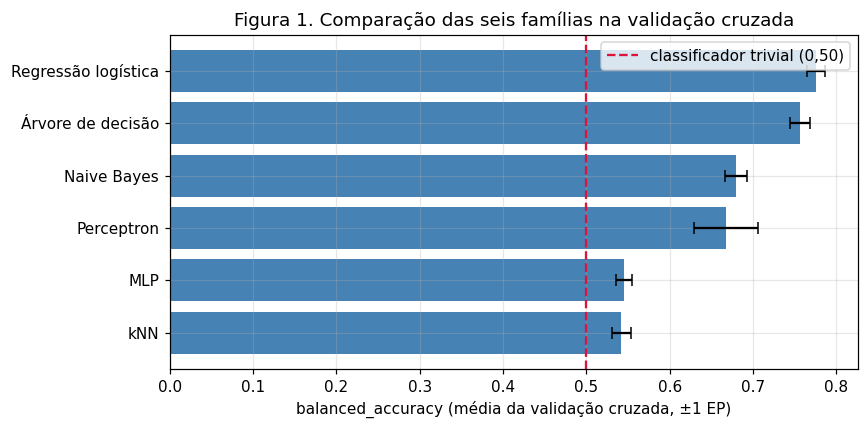

In [ ]:
# Gráfico: média de CV com barra de ±1 erro padrão
fig, ax = plt.subplots(figsize=(8, 4))
ordem = tabela_cv.sort_values('média CV')
ax.barh(ordem['família'], ordem['média CV'],
        xerr=ordem['erro padrão'], capsize=4, color='steelblue')
ax.axvline(0.5, color='crimson', ls='--', label='classificador trivial (0,50)')
ax.set_xlabel(f'{METRICA} (média da validação cruzada, ±1 EP)')
ax.set_title('Figura 1. Comparação das seis famílias na validação cruzada')
ax.legend()
plt.tight_layout(); plt.show()


In [ ]:
primeiro,segundo=tabela_cv.iloc[0],tabela_cv.iloc[1]
mais_caro=tabela_cv.loc[tabela_cv['tempo (s)'].idxmax()]
display(Markdown(f"""### Leitura dos resultados de CV
**{primeiro['família']}** lidera com {primeiro['média CV']:.4f} ± {primeiro['erro padrão']:.4f} EP;
{segundo['família']} vem em seguida com {segundo['média CV']:.4f} ± {segundo['erro padrão']:.4f}.
A diferença de médias é {primeiro['média CV']-segundo['média CV']:.4f}.
Essa ordenação seleciona o campeão, mas a sobreposição (ou não) das barras não demonstra
equivalência nem significância estatística. A busca e a comparação reutilizam os mesmos folds.

A busca mais cara foi {mais_caro['família']} ({mais_caro['tempo (s)']:.1f} s, incluindo extensões).
As diferenças combinam representação, hiperparâmetros e tratamento de classes. Sem uma ablação
controlada, não é possível atribuir a liderança apenas a `class_weight` ou à capacidade do algoritmo.
"""))


### Leitura dos resultados de CV
**Regressão logística** lidera com 0.7757 ± 0.0109 EP;
Árvore de decisão vem em seguida com 0.7567 ± 0.0120.
A diferença de médias é 0.0190.
Essa ordenação seleciona o campeão, mas a sobreposição (ou não) das barras não demonstra
equivalência nem significância estatística. A busca e a comparação reutilizam os mesmos folds.

A busca mais cara foi MLP (839.8 s, incluindo extensões).
As diferenças combinam representação, hiperparâmetros e tratamento de classes. Sem uma ablação
controlada, não é possível atribuir a liderança apenas a `class_weight` ou à capacidade do algoritmo.


## Seção 6 - Estudo de overfitting, viés e variância
### 6.1 Lacuna por família
A lacuna é média de treino menos média de validação nos mesmos folds, para o campeão de cada
família. Uma lacuna positiva grande é compatível com sobreajuste; não é uma medida isolada
da variância estatística. Escores baixos e próximos podem sugerir subajuste, mas também
desbalanceamento, representação inadequada ou dificuldade de otimização.

,família,média treino,média CV,lacuna
0,kNN,1.0000,0.5421,0.4579
1,MLP,0.8404,0.5451,0.2953
2,Árvore de decisão,0.7860,0.7567,0.0294
3,Naive Bayes,0.6929,0.6796,0.0133
4,Regressão logística,0.7764,0.7757,0.0007
5,Perceptron,0.6683,0.6680,0.0003


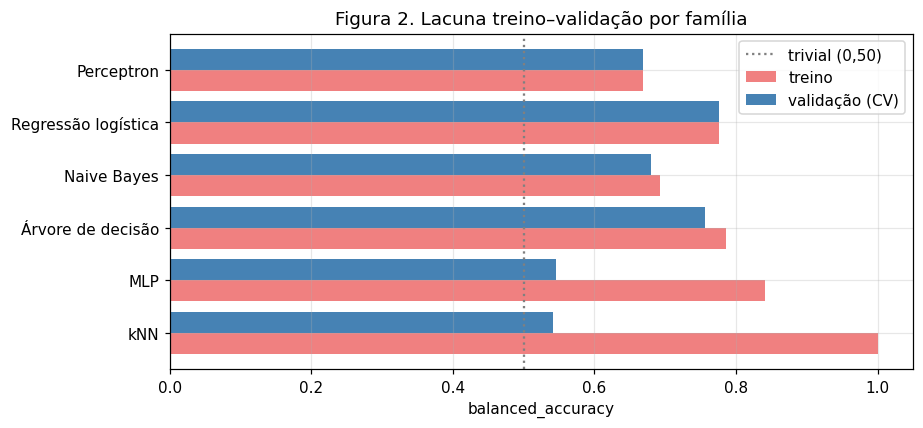

In [ ]:
lacunas = tabela_cv[['família', 'média treino', 'média CV']].copy()
lacunas['lacuna'] = lacunas['média treino'] - lacunas['média CV']
lacunas = lacunas.sort_values('lacuna', ascending=False).reset_index(drop=True)
display(lacunas.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4))
pos = np.arange(len(lacunas))
ax.barh(pos - 0.2, lacunas['média treino'], height=0.4, label='treino', color='lightcoral')
ax.barh(pos + 0.2, lacunas['média CV'],     height=0.4, label='validação (CV)', color='steelblue')
ax.set_yticks(pos); ax.set_yticklabels(lacunas['família'])
ax.axvline(0.5, color='gray', ls=':', label='trivial (0,50)')
ax.set_xlabel(METRICA)
ax.set_title('Figura 2. Lacuna treino–validação por família')
ax.legend()
plt.tight_layout(); plt.show()


In [ ]:
for _,r in lacunas.iterrows():
    display(Markdown(f"- **{r['família']}**: treino {r['média treino']:.4f}, CV {r['média CV']:.4f}, lacuna {r['lacuna']:+.4f}."))
display(Markdown("No kNN ponderado por distância, os próprios exemplos têm distância zero no escore de treino. Por isso uma lacuna grande precisa ser interpretada junto à curva de validação, e não como prova isolada de que k=1 foi escolhido."))


- **kNN**: treino 1.0000, CV 0.5421, lacuna +0.4579.

- **MLP**: treino 0.8404, CV 0.5451, lacuna +0.2953.

- **Árvore de decisão**: treino 0.7860, CV 0.7567, lacuna +0.0294.

- **Naive Bayes**: treino 0.6929, CV 0.6796, lacuna +0.0133.

- **Regressão logística**: treino 0.7764, CV 0.7757, lacuna +0.0007.

- **Perceptron**: treino 0.6683, CV 0.6680, lacuna +0.0003.

No kNN ponderado por distância, os próprios exemplos têm distância zero no escore de treino. Por isso uma lacuna grande precisa ser interpretada junto à curva de validação, e não como prova isolada de que k=1 foi escolhido.

### 6.2 Curvas e regra de 1 EP
As curvas mantêm os demais hiperparâmetros do campeão de cada família e variam somente o eixo
indicado. Faixas de treino e validação mostram ±1 EP amostral. O limiar é melhor média menos
o EP dessa melhor média. Entre candidatos acima do limiar, escolhe-se a menor profundidade,
o maior k ou o maior alpha, respectivamente. É uma heurística de simplicidade, não um teste
de equivalência. Com voto por distância, aumentar k não elimina a interpolação no treino.

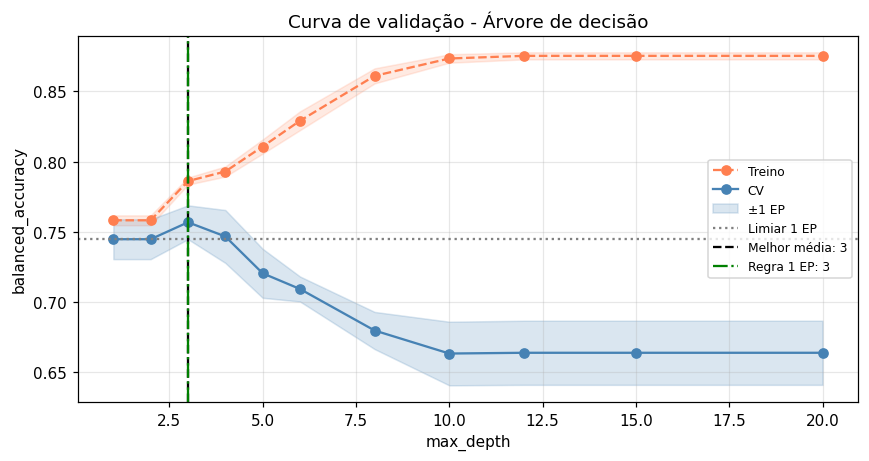

,max_depth,treino,CV,EP treino,EP CV
0,1,0.7581,0.7446,0.0035,0.0142
1,2,0.7581,0.7446,0.0035,0.0142
2,3,0.7861,0.7567,0.0025,0.0120
3,4,0.7929,0.7466,0.0036,0.0188
4,5,0.8106,0.7204,0.0050,0.0175
5,6,0.8290,0.7092,0.0067,0.0089
6,8,0.8610,0.6796,0.0053,0.0132
7,10,0.8734,0.6632,0.0030,0.0227
8,12,0.8753,0.6637,0.0025,0.0228
9,15,0.8753,0.6637,0.0025,0.0228


**Árvore de decisão:** melhor média em max_depth=3 (CV 0.7567); a regra de 1 EP escolhe 3 (CV 0.7567). Nos extremos do eixo, as lacunas treino–CV são +0.0135 e +0.2116. Avisos de convergência nesta curva: 0.

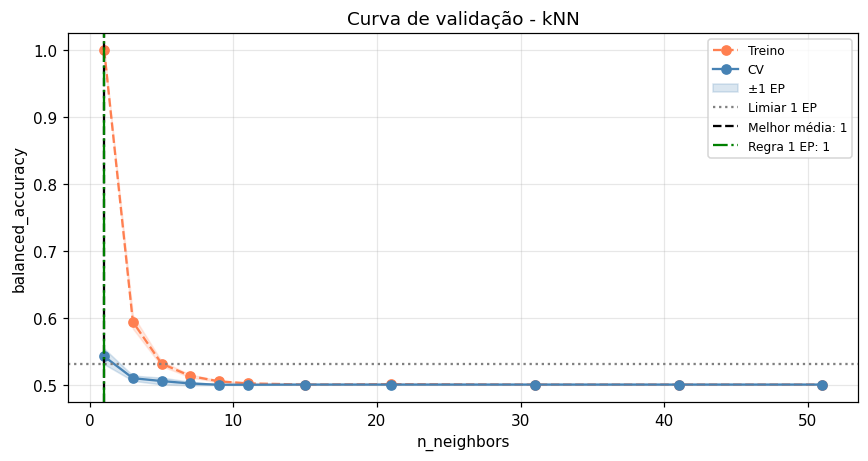

,n_neighbors,treino,CV,EP treino,EP CV
0,1,1.0000,0.5421,0.0000,0.0116
1,3,0.5936,0.5095,0.0101,0.0039
2,5,0.5313,0.5053,0.0037,0.0051
3,7,0.5128,0.5016,0.0021,0.0026
4,9,0.5048,0.4997,0.0013,0.0003
5,11,0.5018,0.4997,0.0008,0.0003
6,15,0.5000,0.5000,0.0000,0.0000
7,21,0.5006,0.5000,0.0006,0.0000
8,31,0.5000,0.5000,0.0000,0.0000
9,41,0.5000,0.5000,0.0000,0.0000


**kNN:** melhor média em n_neighbors=1 (CV 0.5421); a regra de 1 EP escolhe 1 (CV 0.5421). Nos extremos do eixo, as lacunas treino–CV são +0.4579 e +0.0000. Avisos de convergência nesta curva: 0.

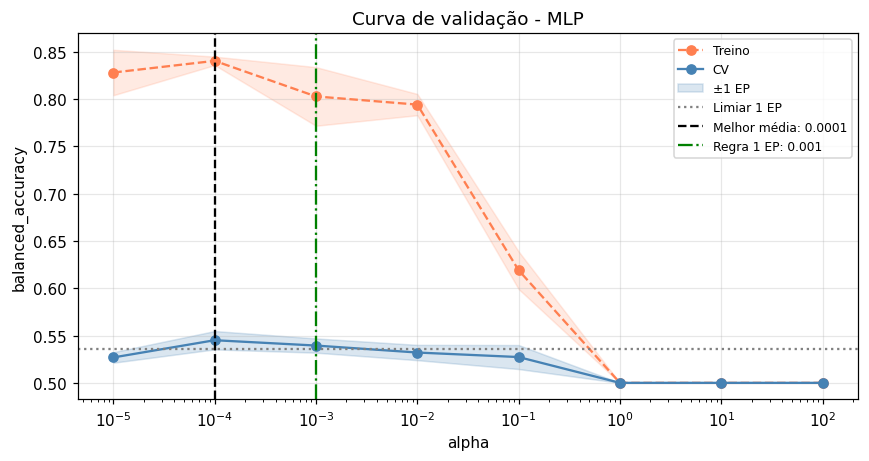

,alpha,treino,CV,EP treino,EP CV
0,1.0000e-05,0.8280,0.5269,0.0240,0.0056
1,1.0000e-04,0.8404,0.5451,0.0045,0.0097
2,1.0000e-03,0.8027,0.5394,0.0310,0.0075
3,1.0000e-02,0.7941,0.5321,0.0112,0.0081
4,1.0000e-01,0.6190,0.5273,0.0199,0.0127
5,1.0000e+00,0.5000,0.5000,0.0000,0.0000
6,1.0000e+01,0.5000,0.5000,0.0000,0.0000
7,1.0000e+02,0.5000,0.5000,0.0000,0.0000


**MLP:** melhor média em alpha=0.0001 (CV 0.5451); a regra de 1 EP escolhe 0.001 (CV 0.5394). Nos extremos do eixo, as lacunas treino–CV são +0.3012 e +0.0000. Avisos de convergência nesta curva: 0.

In [ ]:
curvas = {}
for nome, param, faixa in [
    ('Árvore de decisão', 'modelo__max_depth', config['curvas']['arvore']),
    ('kNN', 'modelo__n_neighbors', config['curvas']['knn']),
    ('MLP', 'modelo__alpha', config['curvas']['mlp'])
]:
    chave = 'curva_' + nome_arquivo(nome)
    curva = carregar_etapa(chave)
    if curva is None:
        print('Calculando curva:', nome, flush=True)
        inicio = time.perf_counter()
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter('always', ConvergenceWarning)
            tr, va = validation_curve(
                clone(buscas[nome]['busca'].best_estimator_), X_dev, y_dev,
                param_name=param, param_range=faixa, cv=FOLDS,
                scoring=METRICA, n_jobs=1, error_score='raise')
        curva = {'faixa': np.asarray(faixa), 'treino': tr, 'validacao': va,
                 'avisos': [str(w.message) for w in avisos if issubclass(w.category, ConvergenceWarning)],
                 'tempo': time.perf_counter() - inicio}
        salvar_etapa(chave, curva)
    curvas[nome] = curva
resumo_curvas=[]

for nome,d in curvas.items():
    x=d['faixa']; tr=d['treino']; va=d['validacao']
    mt,mv=tr.mean(axis=1),va.mean(axis=1)
    et,ev=tr.std(axis=1,ddof=1)/np.sqrt(K_FOLDS),va.std(axis=1,ddof=1)/np.sqrt(K_FOLDS)
    ib=int(np.argmax(mv)); limiar=mv[ib]-ev[ib]; elegiveis=np.flatnonzero(mv>=limiar)
    i1=int(elegiveis[0] if nome=='Árvore de decisão' else elegiveis[-1])
    eixo={'Árvore de decisão':'max_depth','kNN':'n_neighbors','MLP':'alpha'}[nome]
    fig,ax=plt.subplots(figsize=(8,4.3))
    ax.plot(x,mt,'o--',color='coral',label='Treino'); ax.fill_between(x,mt-et,mt+et,color='coral',alpha=.16)
    ax.plot(x,mv,'o-',color='steelblue',label='CV'); ax.fill_between(x,mv-ev,mv+ev,color='steelblue',alpha=.2,label='±1 EP')
    ax.axhline(limiar,color='gray',ls=':',label='Limiar 1 EP')
    ax.axvline(x[ib],color='black',ls='--',label=f'Melhor média: {x[ib]:g}')
    ax.axvline(x[i1],color='green',ls='-.',label=f'Regra 1 EP: {x[i1]:g}')
    if nome=='MLP': ax.set_xscale('log')
    ax.set(xlabel=eixo,ylabel=METRICA,title=f'Curva de validação - {nome}')
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()
    display(pd.DataFrame({eixo:x,'treino':mt,'CV':mv,'EP treino':et,'EP CV':ev}).round(5))
    display(Markdown(f"**{nome}:** melhor média em {eixo}={x[ib]:g} (CV {mv[ib]:.4f}); a regra de 1 EP escolhe {x[i1]:g} (CV {mv[i1]:.4f}). Nos extremos do eixo, as lacunas treino–CV são {mt[0]-mv[0]:+.4f} e {mt[-1]-mv[-1]:+.4f}. Avisos de convergência nesta curva: {len(d['avisos'])}."))
    resumo_curvas.append({'família':nome,'melhor':float(x[ib]),'1 EP':float(x[i1]),'CV melhor':float(mv[ib])})


In [ ]:
for nome, d in curvas.items():
    tr, va = d['treino'].mean(axis=1), d['validacao'].mean(axis=1)
    if nome == 'MLP':
        leitura = 'Alpha maior aumenta a regularização, mantida a arquitetura.'
        if tr[-1] < tr[0] and va[-1] < va[0]:
            leitura += ' Neste intervalo, o extremo mais regularizado reduz os dois escores.'
    elif nome == 'kNN':
        pesos = buscas[nome]['busca'].best_params_['modelo__weights']
        leitura = f'Votação selecionada: {pesos}. k maior suaviza a decisão local.'
        if pesos == 'distance':
            leitura += ' Distância zero dos próprios exemplos pode elevar o escore de treino.'
    else:
        leitura = 'Profundidade maior amplia a capacidade da árvore.'
        if tr[-1] > tr[0] and va[-1] < va[0]:
            leitura += ' Melhora no treino e piora na CV entre os extremos são compatíveis com sobreajuste.'
    display(Markdown(
        f"**{nome}:** treino {tr[0]:.4f} → {tr[-1]:.4f}; "
        f"CV {va[0]:.4f} → {va[-1]:.4f} entre os extremos. {leitura}"))
display(Markdown('Uma lacuna pequena deve ser interpretada junto ao nível dos escores. '
                 'Valores próximos de 0,50 podem indicar baixa capacidade discriminativa. '
                 'As curvas são condicionais aos demais hiperparâmetros selecionados; '
                 'não constituem uma decomposição formal do erro em viés e variância.'))


**Árvore de decisão:** treino 0.7581 → 0.8753; CV 0.7446 → 0.6637 entre os extremos. Profundidade maior amplia a capacidade da árvore. Melhora no treino e piora na CV entre os extremos são compatíveis com sobreajuste.

**kNN:** treino 1.0000 → 0.5000; CV 0.5421 → 0.5000 entre os extremos. Votação selecionada: uniform. k maior suaviza a decisão local.

**MLP:** treino 0.8280 → 0.5000; CV 0.5268 → 0.5000 entre os extremos. Alpha maior aumenta a regularização, mantida a arquitetura. Neste intervalo, o extremo mais regularizado reduz os dois escores.

Uma lacuna pequena deve ser interpretada junto ao nível dos escores. Valores próximos de 0,50 podem indicar baixa capacidade discriminativa. As curvas são condicionais aos demais hiperparâmetros selecionados; não constituem uma decomposição formal do erro em viés e variância.

### 6.3 Estudo das implementações autorais
As classes definidas na Seção 4 são avaliadas no mesmo desenvolvimento, nos mesmos cinco
folds e com o mesmo Pipeline. A métrica de seleção é a acurácia balanceada.

- **Perceptron:** 50 e 1.002 épocas; taxa 0,005 e tratamento autoral do desbalanceamento.
- **MLP:** uma camada oculta; 1 e 10 neurônios; 4 e 100 épocas; taxa 0,005;
  reamostragem aleatória apenas no treino de cada fold.

Todas as configurações são exibidas. Esta grade adicional estuda sensibilidade à capacidade
e às épocas, sem extensão automática. As implementações autorais não substituem os campeões
da comparação principal. O estudo é exploratório em razão do histórico de acesso a resultados.

In [ ]:
def refazer_cv_autoral(modelo, grade):
    scoring={'balanceada':'balanced_accuracy','acuracia':'accuracy',
        'recall':make_scorer(recall_score,zero_division=0),
        'precisao':make_scorer(precision_score,zero_division=0),
        'f1':make_scorer(f1_score,zero_division=0),'auc':'roc_auc'}
    busca=GridSearchCV(montar_pipeline(modelo),grade,cv=FOLDS,scoring=scoring,
        refit=False,n_jobs=1,return_train_score=True,error_score='raise')
    inicio=time.perf_counter()
    busca.fit(X_dev,y_dev)
    resultados=[]
    for i,parametros in enumerate(busca.cv_results_['params']):
        linha={'parametros':parametros}
        for metrica in scoring:
            valores=np.array([busca.cv_results_[f'split{k}_test_{metrica}'][i] for k in range(K_FOLDS)])
            linha[metrica]={'folds':valores.tolist(),'media':float(valores.mean()),
                'desvio':float(valores.std(ddof=1)),'ep':float(valores.std(ddof=1)/np.sqrt(K_FOLDS))}
        linha['treino_balanceada']=float(busca.cv_results_['mean_train_balanceada'][i])
        linha['lacuna']=linha['treino_balanceada']-linha['balanceada']['media']
        resultados.append(linha)
    melhor=int(np.argmax([l['balanceada']['media'] for l in resultados]))
    return {'candidatos':resultados,'melhor_indice':melhor,'melhor':resultados[melhor],
        'tempo_total_s':time.perf_counter()-inicio,'avaliacao_teste_autoral':False}


resultados_autorais = {}
for familia, modelo in MODELOS_AUTORAIS.items():
    arquivo = ARTEFATOS / f'cv_autoral_{familia}.json'
    if arquivo.exists():
        estudo = ler_json(arquivo)
        assert estudo['hash_protocolo'] == HASH_PROTOCOLO
        assert not estudo['avaliacao_teste_autoral']
        print('CV autoral recuperada:', familia)
    else:
        assert not TRAVA_TESTE.exists(), 'Não iniciar desenvolvimento após registro do teste.'
        print('Executando CV autoral:', familia, flush=True)
        estudo = refazer_cv_autoral(modelo, GRADE_AUTORAL[familia])
        estudo['hash_protocolo'] = HASH_PROTOCOLO
        estudo['concluido_em'] = agora()
        salvar_json(arquivo, estudo)
    resultados_autorais[familia] = estudo


CV autoral recuperada: perceptron
CV autoral recuperada: mlp


In [ ]:
linhas_autorais=[]
for familia,estudo in resultados_autorais.items():
    for indice,candidato in enumerate(estudo['candidatos']):
        p=candidato['parametros']
        linhas_autorais.append({'família autoral':familia,'épocas':p['modelo__epocas'],
            'neurônios':p.get('modelo__j','—'),
            'CV balanceada':candidato['balanceada']['media'],'EP':candidato['balanceada']['ep'],
            'acurácia':candidato['acuracia']['media'],'recall AVC':candidato['recall']['media'],
            'precisão AVC':candidato['precisao']['media'],'F1 AVC':candidato['f1']['media'],
            'AUC':candidato['auc']['media'],'treino balanceada':candidato['treino_balanceada'],
            'lacuna':candidato['lacuna'],'melhor nesta grade':indice==estudo['melhor_indice']})
tabela_autoral=pd.DataFrame(linhas_autorais)
display(tabela_autoral[['família autoral','épocas','neurônios','CV balanceada','EP','melhor nesta grade']].round(4))
display(tabela_autoral[['família autoral','épocas','neurônios','acurácia','recall AVC','precisão AVC','F1 AVC','AUC']].round(4))
display(tabela_autoral[['família autoral','épocas','neurônios','treino balanceada','CV balanceada','lacuna']].round(4))


,família autoral,épocas,neurônios,CV balanceada,EP,melhor nesta grade
0,perceptron,50,—,0.5362,0.0258,True
1,perceptron,1002,—,0.5132,0.0080,False
2,mlp,4,1,0.5000,0.0000,False
3,mlp,4,10,0.7599,0.0147,True
4,mlp,100,1,0.5000,0.0000,False
5,mlp,100,10,0.6928,0.0282,False


,família autoral,épocas,neurônios,acurácia,recall AVC,precisão AVC,F1 AVC,AUC
0,perceptron,50,—,0.9182,0.1121,0.0857,0.0814,0.6903
1,perceptron,1002,—,0.9302,0.0501,0.0734,0.0575,0.6226
2,mlp,4,1,0.0497,1.0000,0.0497,0.0947,0.7515
3,mlp,4,10,0.7114,0.8137,0.1265,0.2189,0.8366
4,mlp,100,1,0.9503,0.0000,0.0000,0.0000,0.7825
5,mlp,100,10,0.7789,0.5972,0.1321,0.2154,0.7740


,família autoral,épocas,neurônios,treino balanceada,CV balanceada,lacuna
0,perceptron,50,—,0.5481,0.5362,0.0119
1,perceptron,1002,—,0.5241,0.5132,0.0109
2,mlp,4,1,0.5000,0.5000,0.0000
3,mlp,4,10,0.7850,0.7599,0.0252
4,mlp,100,1,0.5000,0.5000,0.0000
5,mlp,100,10,0.8248,0.6928,0.1320


In [ ]:
for familia,estudo in resultados_autorais.items():
    melhor=estudo['melhor']
    display(Markdown(f"**{familia.capitalize()} autoral:** melhor nesta grade: `{melhor['parametros']}`; "
        f"CV balanceada **{melhor['balanceada']['media']:.4f} ± {melhor['balanceada']['ep']:.4f} EP**, "
        f"recall {melhor['recall']['media']:.4f}, precisão {melhor['precisao']['media']:.4f}; "
        f"lacuna treino−CV {melhor['lacuna']:+.4f}. Tempo da busca registrada: {estudo['tempo_total_s']/60:.2f} min."))
    pior=min(estudo['candidatos'],key=lambda r:r['balanceada']['media'])
    display(Markdown(f"Faixa observada de CV balanceada: {pior['balanceada']['media']:.4f} a "
        f"{melhor['balanceada']['media']:.4f}. São resultados de desenvolvimento, sem seleção de um novo campeão de teste."))
    if melhor['recall']['media'] < 0.1:
        display(Markdown('**Limitação observada:** o recall médio ficou abaixo de 10%. '
            'A acurácia global, isoladamente, não sustenta uma boa identificação da classe AVC. '
            'A pequena lacuna treino−CV também não demonstra bom desempenho: ambos os escores precisam ser considerados.'))
curta=next(c for c in resultados_autorais['mlp']['candidatos'] if c['parametros']=={'modelo__epocas':4,'modelo__j':10})
longa=next(c for c in resultados_autorais['mlp']['candidatos'] if c['parametros']=={'modelo__epocas':100,'modelo__j':10})

diagnostico = (
    'Aumento do treino acompanhado de redução na CV é compatível com sobreajuste nesta comparação.'
    if longa['treino_balanceada'] > curta['treino_balanceada'] and longa['balanceada']['media'] < curta['balanceada']['media']
    else 'Os valores desta comparação não mostram simultaneamente aumento no treino e redução na CV.'
)
display(Markdown(
    f"**MLP de 10 neurônios, 4 → 100 épocas:** treino "
    f"{curta['treino_balanceada']:.4f} → {longa['treino_balanceada']:.4f}; "
    f"CV {curta['balanceada']['media']:.4f} → {longa['balanceada']['media']:.4f}; "
    f"lacuna {curta['lacuna']:.4f} → {longa['lacuna']:.4f}. {diagnostico}"))


**Perceptron autoral:** melhor nesta grade: `{'modelo__epocas': 50}`; CV balanceada **0.5362 ± 0.0258 EP**, recall 0.1121, precisão 0.0857; lacuna treino−CV +0.0119. Tempo da busca registrada: 4.37 min.

Faixa observada de CV balanceada: 0.5132 a 0.5362. São resultados de desenvolvimento, sem seleção de um novo campeão de teste.

**Mlp autoral:** melhor nesta grade: `{'modelo__epocas': 4, 'modelo__j': 10}`; CV balanceada **0.7599 ± 0.0147 EP**, recall 0.8137, precisão 0.1265; lacuna treino−CV +0.0252. Tempo da busca registrada: 9.32 min.

Faixa observada de CV balanceada: 0.5000 a 0.7599. São resultados de desenvolvimento, sem seleção de um novo campeão de teste.

**MLP de 10 neurônios, 4 → 100 épocas:** treino 0.7850 → 0.8248; CV 0.7599 → 0.6928; lacuna 0.0252 → 0.1320. Aumento do treino acompanhado de redução na CV é compatível com sobreajuste nesta comparação.

## Seção 7 - Avaliação final no teste
Os campeões são declarados pela média de CV, com desempate pelo nome da família.
Cada Pipeline selecionado é reajustado no desenvolvimento completo durante a busca.
A avaliação utiliza essas configurações; a classificação dos campeões não é alterada
pelos resultados do teste. O registro inclui data, protocolo, declaração e previsões.
As reexecuções recuperam as previsões persistidas.

**Registro experimental:** a E1 contém avaliação de teste. Esta versão usa a divisão com semente 10 e resultados separados. A correção da divisão não elimina o histórico de acesso anterior ao teste.

In [ ]:
NOME_CAMPEAO = str(tabela_cv.iloc[0]['família'])
declaracao = normalizar({
    'hash_protocolo': HASH_PROTOCOLO, 'campeao_geral': NOME_CAMPEAO,
    'campeoes': {n: info['busca'].best_params_ for n, info in buscas.items()},
    'medias_cv': {n: float(info['busca'].best_score_) for n, info in buscas.items()}
})
ARQ_DECLARACAO = ARTEFATOS / 'campeoes_declarados.json'
if ARQ_DECLARACAO.exists():
    assert ler_json(ARQ_DECLARACAO) == declaracao
else:
    assert not TRAVA_TESTE.exists(), 'Declaração deve anteceder o teste.'
    salvar_json(ARQ_DECLARACAO, declaracao)
display(Markdown(f'**Campeão selecionado pelo desenvolvimento: {NOME_CAMPEAO}.**'))
for nome, parametros in declaracao['campeoes'].items():
    print(nome, parametros)


**Campeão selecionado pelo desenvolvimento: Regressão logística.**

Árvore de decisão {'modelo__criterion': 'gini', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 20}
kNN {'modelo__n_neighbors': 1, 'modelo__p': 1, 'modelo__weights': 'uniform'}
Naive Bayes {'modelo__var_smoothing': 9.999999999999999e-14}
Regressão logística {'modelo__C': 0.01, 'modelo__class_weight': 'balanced'}
Perceptron {'modelo__alpha': 0.0001, 'modelo__class_weight': 'balanced', 'modelo__eta0': 100.0}
MLP {'modelo__alpha': 0.0001, 'modelo__hidden_layer_sizes': [32, 16]}


In [ ]:
ARQ_RESULTADO = ARTEFATOS / 'resultado_teste_semente10.json'
ARQ_INICIO = TRAVA_TESTE

resultado = None

if ARQ_RESULTADO.exists():
    assert ARQ_INICIO.exists(), (
        'Resultado sem registro de início: conferir a procedência.'
    )

    inicio_teste = json.loads(
        ARQ_INICIO.read_text(encoding='utf-8')
    )

    assert inicio_teste['hash_protocolo'] == HASH_PROTOCOLO
    assert inicio_teste['declaracao'] == declaracao

    resultado = json.loads(
        ARQ_RESULTADO.read_text(encoding='utf-8')
    )

    print('Previsões persistidas recuperadas.')

elif ARQ_INICIO.exists():
    raise RuntimeError(
        'O teste foi iniciado, mas falta o resultado completo. '
        'Preserve os registros; não repita automaticamente.'
    )

elif EXECUTAR_TESTE_SEMENTE10:
    assert all(
        (ARTEFATOS / f'cv_autoral_{n}.json').exists()
        for n in ['perceptron', 'mlp']
    ), 'Conclua o estudo autoral da Seção 6.3 antes da avaliação.'

    inicio_teste = {
        'hash_protocolo': HASH_PROTOCOLO,
        'semente': SEMENTE,
        'data_hora': datetime.datetime.now(
            datetime.timezone.utc
        ).isoformat(),
        'declaracao': declaracao,
        'historico': (
            'Houve acesso anterior ao teste da E1 '
            'e resultados da E2 com semente 42.'
        )
    }

    # Criação exclusiva: não sobrescreve um início de teste existente.
    with ARQ_INICIO.open('x', encoding='utf-8') as arquivo:
        json.dump(
            inicio_teste,
            arquivo,
            ensure_ascii=False,
            indent=2
        )

    modelos_teste = {}

    for nome, info in buscas.items():
        modelo = info['busca'].best_estimator_

        # O modelo já foi ajustado no desenvolvimento.
        pred = modelo.predict(X_teste)

        if hasattr(modelo, 'predict_proba'):
            coluna = list(modelo.classes_).index(1)
            score = modelo.predict_proba(X_teste)[:, coluna]
        else:
            score = modelo.decision_function(X_teste)

        assert np.isfinite(score).all()

        modelos_teste[nome] = {
            'pred': pred.tolist(),
            'score': np.asarray(score).tolist()
        }
        salvar_json(ARTEFATOS / ('teste_parcial_' + nome_arquivo(nome) + '.json'), {
            'hash_protocolo': HASH_PROTOCOLO, 'familia': nome,
            'indices': X_teste.index.tolist(), 'resultado': modelos_teste[nome]
        })

    resultado = {
        **inicio_teste,
        'indices': X_teste.index.tolist(),
        'y_true': y_teste.tolist(),
        'modelos': modelos_teste
    }

    temporario = ARQ_RESULTADO.with_suffix('.tmp')

    temporario.write_text(
        json.dumps(resultado, ensure_ascii=False, indent=2),
        encoding='utf-8'
    )
    temporario.replace(ARQ_RESULTADO)
    pd.DataFrame([{'familia': n, 'data_hora': inicio_teste['data_hora'],
        'hash_protocolo': HASH_PROTOCOLO, 'semente': SEMENTE, 'event': 'avaliacao'}
        for n in modelos_teste]).to_csv(ARTEFATOS / 'test_log.csv', index=False)

    print(
        'Nova avaliação registrada para o protocolo corrigido. '
        'Histórico anterior preservado.'
    )

else:
    pass

TESTE_DISPONIVEL = resultado is not None
tabela_teste = None

if TESTE_DISPONIVEL:
    assert resultado['hash_protocolo'] == HASH_PROTOCOLO
    assert resultado['semente'] == SEMENTE
    assert resultado['declaracao'] == declaracao
    assert resultado['indices'] == X_teste.index.tolist()
    assert resultado['y_true'] == y_teste.tolist()
    assert set(resultado['modelos']) == set(buscas)

    y_final = np.asarray(resultado['y_true'])
    linhas_teste = []

    for nome, d in resultado['modelos'].items():
        pred = np.asarray(d['pred'])

        linhas_teste.append({
            'família': nome,
            'CV (desenvolvimento)': declaracao['medias_cv'][nome],
            'acurácia balanceada': balanced_accuracy_score(
                y_final, pred
            ),
            'acurácia': accuracy_score(y_final, pred),
            'F1 (AVC)': f1_score(
                y_final, pred, zero_division=0
            ),
            'revocação (AVC)': recall_score(
                y_final, pred, zero_division=0
            ),
            'precisão (AVC)': precision_score(
                y_final, pred, zero_division=0
            ),
            'AUC-ROC': roc_auc_score(y_final, d['score'])
        })

    tabela_teste = pd.DataFrame(linhas_teste).sort_values(
        ['CV (desenvolvimento)', 'família'],
        ascending=[False, True]
    ).reset_index(drop=True)

    tabela_teste['diferença (teste − CV)'] = (
        tabela_teste['acurácia balanceada']
        - tabela_teste['CV (desenvolvimento)']
    )

    display(tabela_teste.round(4))

    tabela_teste.to_csv(
        ARTEFATOS / 'tabela_teste.csv',
        index=False
    )


Previsões persistidas recuperadas.


,família,CV (desenvolvimento),acurácia balanceada,acurácia,F1 (AVC),revocação (AVC),precisão (AVC),AUC-ROC,diferença (teste − CV)
0,Regressão logística,0.7757,0.7565,0.7533,0.2360,0.76,0.1397,0.8410,-0.0192
1,Árvore de decisão,0.7567,0.7354,0.7312,0.2164,0.74,0.1267,0.8169,-0.0213
2,Naive Bayes,0.6796,0.6971,0.8385,0.2512,0.54,0.1636,0.8188,0.0175
3,Perceptron,0.6680,0.7346,0.5858,0.1789,0.90,0.0993,0.7959,0.0666
4,MLP,0.5451,0.5363,0.9288,0.1235,0.10,0.1613,0.7283,-0.0088
5,kNN,0.5421,0.5142,0.9228,0.0723,0.06,0.0909,0.5142,-0.0279


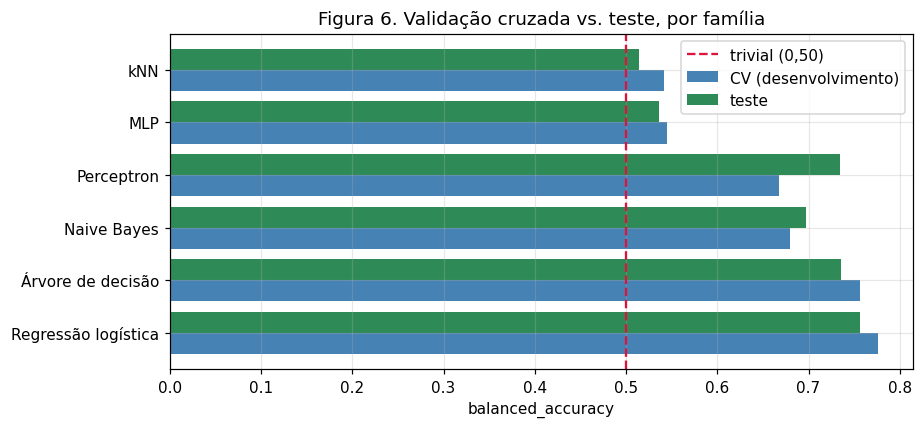

In [ ]:
if TESTE_DISPONIVEL:
    # Comparação visual: validação cruzada vs. teste
    fig, ax = plt.subplots(figsize=(8.5, 4))
    pos = np.arange(len(tabela_teste))
    ax.barh(pos - 0.2, tabela_teste['CV (desenvolvimento)'], height=0.4,
            label='CV (desenvolvimento)', color='steelblue')
    ax.barh(pos + 0.2, tabela_teste['acurácia balanceada'], height=0.4,
            label='teste', color='seagreen')
    ax.set_yticks(pos); ax.set_yticklabels(tabela_teste['família'])
    ax.axvline(0.5, color='crimson', ls='--', label='trivial (0,50)')
    ax.set_xlabel(METRICA)
    ax.set_title('Figura 6. Validação cruzada vs. teste, por família')
    ax.legend()
    plt.tight_layout(); plt.show()


In [ ]:
if TESTE_DISPONIVEL:
    camp=tabela_teste.loc[tabela_teste['família']==NOME_CAMPEAO].iloc[0]
    npositivos=int(y_final.sum())
    display(Markdown(f"""### Discussão CV versus teste
    O campeão **{NOME_CAMPEAO}**, selecionado pelo desenvolvimento, passou de {camp['CV (desenvolvimento)']:.4f}
    na CV para {camp['acurácia balanceada']:.4f} no teste (diferença {camp['diferença (teste − CV)']:+.4f}).
    Há {npositivos} positivos no teste: uma única classificação positiva correta/incorreta altera o
    recall positivo em {1/npositivos:.2%} e a acurácia balanceada em {0.5/npositivos:.2%}.
    Isso evidencia a sensibilidade a poucos casos. O EP da CV não é um intervalo de confiança
    da diferença entre CV e teste; essa diferença combina variação amostral e seleção por CV.
    """))
    for _,r in tabela_teste.iterrows():
        display(Markdown(f"- **{r['família']}**: CV {r['CV (desenvolvimento)']:.4f}; teste {r['acurácia balanceada']:.4f}; diferença {r['diferença (teste − CV)']:+.4f}."))
    display(Markdown('A ordem permanece a da CV. As diferenças no teste são relatadas, sem trocar o campeão, alterar grades ou retornar ao desenvolvimento.'))


### Discussão CV versus teste
    O campeão **Regressão logística**, selecionado pelo desenvolvimento, passou de 0.7757
    na CV para 0.7565 no teste (diferença -0.0192).
    Há 50 positivos no teste: uma única classificação positiva correta/incorreta altera o
    recall positivo em 2.00% e a acurácia balanceada em 1.00%.
    Isso evidencia a sensibilidade a poucos casos. O EP da CV não é um intervalo de confiança
    da diferença entre CV e teste; essa diferença combina variação amostral e seleção por CV.
    

- **Regressão logística**: CV 0.7757; teste 0.7565; diferença -0.0192.

- **Árvore de decisão**: CV 0.7567; teste 0.7354; diferença -0.0213.

- **Naive Bayes**: CV 0.6796; teste 0.6971; diferença +0.0175.

- **Perceptron**: CV 0.6680; teste 0.7346; diferença +0.0666.

- **MLP**: CV 0.5451; teste 0.5363; diferença -0.0088.

- **kNN**: CV 0.5421; teste 0.5142; diferença -0.0279.

A ordem permanece a da CV. As diferenças no teste são relatadas, sem trocar o campeão, alterar grades ou retornar ao desenvolvimento.

In [ ]:
if TESTE_DISPONIVEL:
    display(Markdown(
        f"**Registro de uso do teste** — data e hora (UTC): `{resultado['data_hora']}`  \n"
        f"Protocolo: `{HASH_PROTOCOLO[:16]}…`  \n"
        f"Avaliação única, após a declaração dos campeões. "
        f"Arquivo de início: `{ARQ_INICIO.name}` | resultado: `{ARQ_RESULTADO.name}`"
    ))

**Registro de uso do teste** — data e hora (UTC): `2026-10-26T18:02:17.997777+00:00`  
Protocolo: `301fd117f6449d71…`  
Avaliação única, após a declaração dos campeões. Arquivo de início: `avaliacao_iniciada.json` | resultado: `resultado_teste_semente10.json`

**Extensão opcional declarada (bônus).** Antes de qualquer avaliação adicional,
declaramos a grade e o critério do modelo além do curso:

- **Modelo:** `LGBMClassifier` (LightGBM), ensemble de árvores por *gradient boosting*,
  fora da ementa da disciplina.
- **Grade:** `n_estimators` ∈ {200, 500}; `learning_rate` ∈ {0,03; 0,1};
  `num_leaves` ∈ {15, 31, 63}; `class_weight` ∈ {None, 'balanced'}.
- **Critério de seleção:** maior média de acurácia balanceada na mesma validação
  cruzada estratificada de 5 folds, no mesmo desenvolvimento e no mesmo Pipeline.
- **Decisão sobre o teste:** a extensão é avaliada **apenas no desenvolvimento**.
  O conjunto de teste foi usado uma única vez, na avaliação das seis famílias
  registrada acima, e não é reaberto para a extensão. Essa escolha preserva a
  regra de uso único do teste; em contrapartida, a extensão não produz estimativa
  de generalização independente.

- **Ordem de execução, declarada por transparência:** a extensão foi conduzida
  *após* a avaliação das seis famílias, registrada acima. Por isso mantém cache
  próprio, em `extensao_bonus/`, em vez de usar o controle de etapas do protocolo
  principal — que recusa, por construção, etapas de desenvolvimento gravadas
  depois da trava do teste. A seleção do campeão da extensão usa exclusivamente
  a validação cruzada no desenvolvimento; o conjunto de teste não foi reaberto
  nem consultado em nenhum momento desta extensão.

## Seção 8 - Erros por classe do campeão

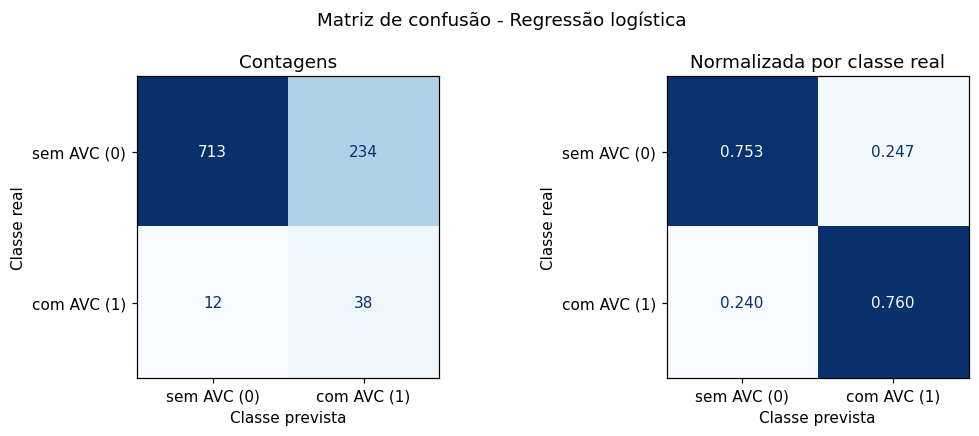

,precision,recall,f1-score,support
sem AVC (0),0.9834,0.7529,0.8529,947.0
com AVC (1),0.1397,0.7600,0.2360,50.0
macro avg,0.5616,0.7565,0.5444,997.0
weighted avg,0.9411,0.7533,0.8219,997.0


Acurácia global: 0.7533


### Interpretação dos erros
    Foram **38 verdadeiros positivos** e **12 falsos negativos**, entre 50 registros de AVC;
    o recall positivo foi 76.00%. Entre os registros sem AVC, houve **713 verdadeiros
    negativos** e **234 falsos positivos**, com recall negativo 75.29%.
    O modelo marcou 272 de 997 registros como positivos (27.28%);
    a precisão positiva foi 13.97%.

    Falso negativo significa um registro com AVC classificado como zero; falso positivo é o inverso.
    O desbalanceamento ajuda a explicar por que falsos positivos podem superar os verdadeiros
    positivos mesmo com recall razoável. Estes números não permitem afirmar que erros seriam
    corrigidos por exames posteriores, que alguém seria liberado sem acompanhamento ou que
    o classificador já seria aceitável para triagem. Tais conclusões exigem avaliação clínica própria.
    

In [ ]:
if TESTE_DISPONIVEL:
    pred_campeao=np.asarray(resultado['modelos'][NOME_CAMPEAO]['pred'])
    fig,eixos=plt.subplots(1,2,figsize=(10,4))
    for ax,norm,fmt,titulo in [(eixos[0],None,'d','Contagens'),(eixos[1],'true','.3f','Normalizada por classe real')]:
        ConfusionMatrixDisplay.from_predictions(y_final,pred_campeao,labels=[0,1],
            display_labels=['sem AVC (0)','com AVC (1)'],normalize=norm,values_format=fmt,
            cmap='Blues',colorbar=False,ax=ax)
        ax.set_title(titulo); ax.set_xlabel('Classe prevista'); ax.set_ylabel('Classe real'); ax.grid(False)
    fig.suptitle(f'Matriz de confusão - {NOME_CAMPEAO}'); plt.tight_layout(); plt.show()
    vn,fp,fn,vp=confusion_matrix(y_final,pred_campeao,labels=[0,1]).ravel()
    relatorio=classification_report(y_final,pred_campeao,labels=[0,1],target_names=['sem AVC (0)','com AVC (1)'],output_dict=True,zero_division=0)
    display(pd.DataFrame({k: v for k, v in relatorio.items() if isinstance(v, dict)}).T.round(4))
    print(f"Acurácia global: {relatorio['accuracy']:.4f}")
    display(Markdown(f"""### Interpretação dos erros
    Foram **{vp} verdadeiros positivos** e **{fn} falsos negativos**, entre {vp+fn} registros de AVC;
    o recall positivo foi {vp/(vp+fn):.2%}. Entre os registros sem AVC, houve **{vn} verdadeiros
    negativos** e **{fp} falsos positivos**, com recall negativo {vn/(vn+fp):.2%}.
    O modelo marcou {vp+fp} de {len(y_final)} registros como positivos ({(vp+fp)/len(y_final):.2%});
    a precisão positiva foi {camp['precisão (AVC)']:.2%}.

    Falso negativo significa um registro com AVC classificado como zero; falso positivo é o inverso.
    O desbalanceamento ajuda a explicar por que falsos positivos podem superar os verdadeiros
    positivos mesmo com recall razoável. Estes números não permitem afirmar que erros seriam
    corrigidos por exames posteriores, que alguém seria liberado sem acompanhamento ou que
    o classificador já seria aceitável para triagem. Tais conclusões exigem avaliação clínica própria.
    """))


## Seção 9 - Conclusões

In [ ]:
lider = tabela_cv.iloc[0]
display(Markdown(
    f"**Síntese do desenvolvimento:** {lider['família']} apresenta a maior média "
    f"de acurácia balanceada nesta comparação: {lider['média CV']:.4f} "
    f"± {lider['erro padrão']:.4f} EP. A ordenação resulta das grades, "
    f"do pré-processamento e dos tratamentos de classe declarados."
))
if TESTE_DISPONIVEL:
    camp = tabela_teste.loc[tabela_teste['família'] == NOME_CAMPEAO].iloc[0]
    display(Markdown(
        f"**Resposta à pergunta no teste:** {NOME_CAMPEAO} obteve acurácia balanceada "
        f"{camp['acurácia balanceada']:.4f}, recall de AVC {camp['revocação (AVC)']:.4f} "
        f"e precisão de AVC {camp['precisão (AVC)']:.4f}. Os números descrevem "
        "a discriminação dos rótulos nesta partição; não demonstram previsão clínica prospectiva."
    ))


**Síntese do desenvolvimento:** Regressão logística apresenta a maior média de acurácia balanceada nesta comparação: 0.7757 ± 0.0109 EP. A ordenação resulta das grades, do pré-processamento e dos tratamentos de classe declarados.

**Resposta à pergunta no teste:** Regressão logística obteve acurácia balanceada 0.7565, recall de AVC 0.7600 e precisão de AVC 0.1397. Os números descrevem a discriminação dos rótulos nesta partição; não demonstram previsão clínica prospectiva.

## Seção 10 - Estudos adicionais
**Extensão bônus (até 0,5 ponto):** realizada com **LightGBM**, modelo de *gradient
boosting* fora da ementa, sob o mesmo protocolo — mesmo desenvolvimento, mesmos cinco
folds, mesmo Pipeline e mesma métrica de seleção. A grade e o critério foram declarados
na Seção 7, antes de qualquer avaliação adicional.

O resultado é negativo e informativo: o LightGBM fica em 3º lugar na validação cruzada,
atrás da regressão logística e da árvore, com lacuna treino−CV de +0,23. A capacidade
extra não compensa a escassez de casos positivos. Registramos a extensão com esse
resultado em vez de descartá-la.

A extensão permanece restrita ao desenvolvimento. O conjunto de teste foi avaliado uma
única vez, na Seção 7, para as seis famílias do protocolo, e não foi reaberto — decisão
que preserva a regra de uso único do teste e que declaramos explicitamente como
limitação da extensão.

**LVQ (opcional):** não incluído nesta entrega.

In [ ]:
# ============================================================
# EXTENSÃO OPCIONAL (bônus): LightGBM, modelo além do curso.
# Mesmo desenvolvimento, mesmos folds, mesmo Pipeline e mesma métrica.
# Avaliado SOMENTE no desenvolvimento: o teste não é reaberto.
# ============================================================
try:
    from lightgbm import LGBMClassifier
    LIGHTGBM_OK = True
except ImportError:
    import subprocess, sys as _sys
    subprocess.run([_sys.executable, '-m', 'pip', '-q', 'install', 'lightgbm'], check=False)
    try:
        from lightgbm import LGBMClassifier
        LIGHTGBM_OK = True
    except ImportError:
        LIGHTGBM_OK = False
        print('LightGBM indisponível neste ambiente: extensão não executada.')

if LIGHTGBM_OK:
    GRADE_BONUS = {
        'modelo__n_estimators':  [200, 500],
        'modelo__learning_rate': [0.03, 0.1],
        'modelo__num_leaves':    [15, 31, 63],
        'modelo__class_weight':  [None, 'balanced'],
    }
    MODELO_BONUS = LGBMClassifier(random_state=SEMENTE, verbose=-1, n_jobs=1)

    # Cache PRÓPRIO da extensão, fora do namespace do protocolo principal.
    # Não usamos carregar_etapa/salvar_etapa de propósito: aquelas funções
    # guardam as etapas das seis famílias e recusam, corretamente, qualquer
    # etapa nova de desenvolvimento registrada depois da trava do teste.
    EXT = RAIZ_NOVA / 'extensao_bonus'
    EXT.mkdir(parents=True, exist_ok=True)
    ARQ_EXT = EXT / 'busca_lightgbm.joblib'
    ARQ_EXT_META = EXT / 'busca_lightgbm.meta.json'

    def carregar_extensao():
        if not ARQ_EXT.exists() or not ARQ_EXT_META.exists():
            return None
        meta = ler_json(ARQ_EXT_META)
        if meta.get('hash_grade') != digest(normalizar(GRADE_BONUS)):
            print('Grade da extensão mudou: cache ignorado.')
            return None
        obj = joblib.load(ARQ_EXT)
        obj['tempo'] = meta['tempo']
        obj['avisos'] = meta['avisos']
        return obj

    def salvar_extensao(obj):
        joblib.dump({'busca': obj['busca']}, ARQ_EXT)
        salvar_json(ARQ_EXT_META, {
            'hash_grade': digest(normalizar(GRADE_BONUS)),
            'tempo': obj['tempo'], 'avisos': obj['avisos'],
            'data_hora': agora(),
            'observacao': ('Extensão opcional avaliada apenas no desenvolvimento. '
                           'O conjunto de teste não foi reaberto.')})

    etapa = carregar_extensao()

    if etapa is None:
        print('Buscando: LightGBM (extensão) ...', flush=True)
        t0 = time.perf_counter()
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter('always', ConvergenceWarning)
            busca_bonus = GridSearchCV(
                estimator=montar_pipeline(MODELO_BONUS),
                param_grid=GRADE_BONUS, scoring=METRICA, cv=FOLDS,
                n_jobs=1, return_train_score=True, refit=True,
                error_score='raise')
            busca_bonus.fit(X_dev, y_dev)
        etapa = {'busca': busca_bonus, 'tempo': time.perf_counter() - t0,
                 'avisos': len([w for w in avisos
                                if issubclass(w.category, ConvergenceWarning)])}
        salvar_extensao(etapa)

    busca_bonus = etapa['busca']
    i = busca_bonus.best_index_
    r = busca_bonus.cv_results_
    sc = np.array([r[f'split{k}_test_score'][i] for k in range(K_FOLDS)])

    linha_bonus = {
        'família': 'LightGBM (extensão)',
        'média CV': sc.mean(),
        'desvio': sc.std(ddof=1),
        'erro padrão': sc.std(ddof=1) / np.sqrt(K_FOLDS),
        'média treino': r['mean_train_score'][i],
        'tempo (s)': etapa['tempo'],
    }
    print('Melhores hiperparâmetros:',
          {k.replace('modelo__', ''): v for k, v in busca_bonus.best_params_.items()})
    print('Bordas da grade:', bordas(GRADE_BONUS, busca_bonus.best_params_) or 'nenhuma')

    comparativo = pd.concat([
        tabela_cv[['família', 'média CV', 'desvio', 'erro padrão', 'média treino', 'tempo (s)']],
        pd.DataFrame([linha_bonus])
    ]).sort_values('média CV', ascending=False).reset_index(drop=True)
    display(comparativo.round(4))

Melhores hiperparâmetros: {'class_weight': 'balanced', 'learning_rate': 0.03, 'n_estimators': 200, 'num_leaves': 15}
Bordas da grade: nenhuma


,família,média CV,desvio,erro padrão,média treino,tempo (s)
0,Regressão logística,0.7757,0.0244,0.0109,0.7764,6.1957
1,Árvore de decisão,0.7567,0.0269,0.0120,0.7860,47.4218
2,LightGBM (extensão),0.6972,0.0237,0.0106,0.9314,54.3231
3,Naive Bayes,0.6796,0.0296,0.0133,0.6929,5.6632
4,Perceptron,0.6680,0.0859,0.0384,0.6683,30.3095
5,MLP,0.5451,0.0217,0.0097,0.8404,839.7644
6,kNN,0.5421,0.0260,0.0116,1.0000,54.4176


In [ ]:
if LIGHTGBM_OK:
    lac = linha_bonus['média treino'] - linha_bonus['média CV']
    pos = int(comparativo.index[comparativo['família'] == 'LightGBM (extensão)'][0]) + 1
    melhor = tabela_cv.iloc[0]
    lac_melhor = melhor['média treino'] - melhor['média CV']
    npos_dev = int((y_dev == 1).sum())

    display(Markdown(f"""### Leitura da extensão

**LightGBM** alcança **{linha_bonus['média CV']:.4f} ± {linha_bonus['erro padrão']:.4f} EP**
de acurácia balanceada, na **{pos}ª posição** do comparativo. {melhor['família']},
a família mais simples do protocolo, obteve {melhor['média CV']:.4f} ± {melhor['erro padrão']:.4f} EP —
uma vantagem de {melhor['média CV'] - linha_bonus['média CV']:.4f}, muito acima da soma
dos dois erros padrão. O modelo além do curso **não supera** o campeão declarado.

O motivo está na lacuna. A extensão marca {linha_bonus['média treino']:.4f} no treino e
{linha_bonus['média CV']:.4f} na validação cruzada, lacuna de **{lac:+.4f}**, contra
{lac_melhor:+.4f} de {melhor['família']}. O *gradient boosting* ajusta resíduos de forma
sequencial e, com {npos_dev} casos positivos em {len(y_dev)} registros — cerca de
{npos_dev / K_FOLDS:.0f} positivos por fold de validação —, essa capacidade se converte
em **variância**, não em sinal. A busca escolheu justamente o canto mais conservador da
grade (`num_leaves`=15, `learning_rate`=0,03, `n_estimators`=200) e nenhuma solução caiu
em borda: a própria validação cruzada rejeitou as configurações mais flexíveis.

A conclusão reforça o resultado do protocolo em vez de contrariá-lo. Para esta base, o
fator determinante é o tratamento do desbalanceamento, não a capacidade da família —
o mesmo padrão já observado entre as seis famílias, onde as sem `class_weight` ficaram
próximas da linha de base trivial. Acrescentar um modelo de maior capacidade sem
acrescentar casos positivos aumenta o ajuste ao desenvolvimento e piora a generalização
estimada.

A busca levou {etapa['tempo'] / 60:.1f} min nos mesmos folds. **A extensão não foi avaliada
no teste:** o conjunto foi usado uma única vez, na Seção 7, para as seis famílias
declaradas. Estes números são de desenvolvimento e não constituem estimativa de
generalização independente.
"""))

### Leitura da extensão

**LightGBM** alcança **0.6972 ± 0.0106 EP**
de acurácia balanceada, na **3ª posição** do comparativo. Regressão logística,
a família mais simples do protocolo, obteve 0.7757 ± 0.0109 EP —
uma vantagem de 0.0785, muito acima da soma
dos dois erros padrão. O modelo além do curso **não supera** o campeão declarado.

O motivo está na lacuna. A extensão marca 0.9314 no treino e
0.6972 na validação cruzada, lacuna de **+0.2342**, contra
+0.0007 de Regressão logística. O *gradient boosting* ajusta resíduos de forma
sequencial e, com 198 casos positivos em 3984 registros — cerca de
40 positivos por fold de validação —, essa capacidade se converte
em **variância**, não em sinal. A busca escolheu justamente o canto mais conservador da
grade (`num_leaves`=15, `learning_rate`=0,03, `n_estimators`=200) e nenhuma solução caiu
em borda: a própria validação cruzada rejeitou as configurações mais flexíveis.

A conclusão reforça o resultado do protocolo em vez de contrariá-lo. Para esta base, o
fator determinante é o tratamento do desbalanceamento, não a capacidade da família —
o mesmo padrão já observado entre as seis famílias, onde as sem `class_weight` ficaram
próximas da linha de base trivial. Acrescentar um modelo de maior capacidade sem
acrescentar casos positivos aumenta o ajuste ao desenvolvimento e piora a generalização
estimada.

A busca levou 0.9 min nos mesmos folds. **A extensão não foi avaliada
no teste:** o conjunto foi usado uma única vez, na Seção 7, para as seis famílias
declaradas. Estes números são de desenvolvimento e não constituem estimativa de
generalização independente.


### Alcance e próximos passos
A seleção e o resumo dos candidatos usam os mesmos folds; o melhor escore de CV pode ser otimista. Os folds compartilham exemplos de treino, e o erro padrão é usado como resumo descritivo. A base é desbalanceada e contém poucos casos positivos, razão pela qual recall e precisão são analisados junto à acurácia balanceada.

As conclusões se referem às grades declaradas. Avisos de convergência e soluções em bordas são apresentados nas tabelas. O histórico de uso do teste, descrito na Seção 7, deve ser considerado ao interpretar generalização. A comparação não estabelece causalidade nem validade clínica.

Em estudos futuros com avaliação independente, podem ser examinados calibração, tratamento do desbalanceamento e limiares definidos apenas no desenvolvimento.

**Autoria:** a concepção do protocolo, as decisões metodológicas, a escolha das grades e dos critérios, a interpretação dos resultados e a redação das análises
são da dupla. As implementações autorais do Perceptron e da MLP foram escritas pela dupla em NumPy, sem bibliotecas de aprendizado.

## Seção 11 - Declaração de uso de IA
**Ferramentas:** Claude (Anthropic), conforme declarado na versão anterior, e Codex (OpenAI).
**Finalidades:** revisão da estrutura, depuração do código, integração dos Pipelines,
persistência de resultados, conferência da divisão e apoio à redação das análises.

**Verificação técnica:** a revisão incluiu comparação com o código e as saídas da E1, testes de gradientes e reprodutibilidade, conferência da reamostragem dentro dos folds e testes do fluxo de persistência. As tabelas e interpretações numéricas deste notebook
são produzidas pelos resultados efetivamente calculados em sua execução.

A dupla é responsável pela revisão e compreensão do código, dos resultados e das decisões apresentadas.

**Referências técnicas:** [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html),
[GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html),
[retropropagação](https://cs231n.github.io/neural-networks-case-study/).

In [ ]:
tempo_buscas = sum(v['tempo'] for v in buscas.values()) / 60
tempo_curvas = sum(v['tempo'] for v in curvas.values()) / 60
tempo_autorais = sum(v['tempo_total_s'] for v in resultados_autorais.values()) / 60
tempo_ext = (etapa['tempo'] / 60) if LIGHTGBM_OK else 0.0

display(pd.DataFrame({
    'etapa': ['Buscas principais', 'Curvas', 'Estudos autorais',
              'Extensão opcional', 'Execução atual'],
    'tempo (min)': [tempo_buscas, tempo_curvas, tempo_autorais, tempo_ext,
                    (time.perf_counter() - T_INICIO) / 60]
}).round(2))

,etapa,tempo (min)
0,Buscas principais,16.40
1,Curvas,3.86
2,Estudos autorais,13.69
3,Extensão opcional,0.91
4,Execução atual,0.18


In [ ]:
import glob
from google.colab import files

caminhos = glob.glob('/content/drive/MyDrive/**/*SEED10*.ipynb', recursive=True)
print('Encontrados:', caminhos)

caminho = caminhos[0]          # ajuste o índice se houver mais de um
!jupyter nbconvert --to html "{caminho}"

html = caminho.replace('.ipynb', '.html')
print('Gerado:', html)
files.download(html)

Encontrados: ['/content/drive/MyDrive/Colab Notebooks/CIN0209_Entrega2_BrainStroke_REFATORADO_SEED10.ipynb']
[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/CIN0209_Entrega2_BrainStroke_REFATORADO_SEED10.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 758484 bytes to /content/drive/MyDrive/Colab Notebooks/CIN0209_Entrega2_BrainStroke_REFATORADO_SEED10.html
Gerado: /content/drive/MyDrive/Colab Notebooks/CIN0209_Entrega2_BrainStroke_REFATORADO_SEED10.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>